# Diabetes Risk Classification: Traditional ML vs Deep Learning

Machine Learning summative project, African Leadership University.

This notebook grows step by step. **Step 2 (this part): Exploratory Data Analysis (EDA).**
Later steps (preprocessing, models, experiments, error analysis) will be added below.

**Goal of the project:** predict whether a person has diabetes from health-survey answers, then compare traditional machine learning (scikit-learn) with deep learning (TensorFlow/Keras).

## 1. Setup
Import the libraries, fix the random seed (so results can be repeated) and find the dataset file.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# The notebook lives in notebooks/, the data lives in dataset/ one folder up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = ROOT / "dataset" / "diabetes_binary_health_indicators_BRFSS2015.csv"
OTHER_FILE = ROOT / "dataset" / "diabetes_012_health_indicators_BRFSS2015.csv"   # 3-class version, only used to check the target
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# Two colours that are easy to tell apart (also for colour-blind readers)
BLUE, ORANGE = "#0072B2", "#D55E00"

def save_and_show(name):
    # Save the current figure in images/ (used later in the report) and display it.
    plt.savefig(IMAGES / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

print("Looking for data in:", DATA_FILE)
print("File found:", DATA_FILE.exists())

Looking for data in: /Users/MAC/Documents/projects/ALU/summative_introduction_to_machine_learning/dataset/diabetes_binary_health_indicators_BRFSS2015.csv
File found: True


## 2. Load the data and take a first look

In [2]:
df = pd.read_csv(DATA_FILE)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("The assignment needs at least 20,000 raw rows ->", "OK" if df.shape[0] >= 20000 else "NOT ENOUGH")
df.head()

Rows: 253680 | Columns: 22
The assignment needs at least 20,000 raw rows -> OK


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Data types: everything is stored as float even though most columns are 0/1 answers
df.dtypes

Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

### What the columns mean
All columns come from the CDC BRFSS 2015 telephone survey (self-reported answers). Short descriptions, based on the dataset documentation and the BRFSS codebook (I will double-check the coding of the last few against the codebook before the report):

| Column | Meaning |
|---|---|
| **Diabetes_binary** | **Target.** 0 = no diabetes, 1 = diabetes |
| HighBP, HighChol | told by a doctor that blood pressure / cholesterol is high (0/1) |
| CholCheck | cholesterol checked in the last 5 years (0/1) |
| BMI | body mass index (number) |
| Smoker | smoked at least 100 cigarettes in life (0/1) |
| Stroke, HeartDiseaseorAttack | ever told they had a stroke / heart disease or heart attack (0/1) |
| PhysActivity | physical activity in the last 30 days, not counting the job (0/1) |
| Fruits, Veggies | eats fruit / vegetables at least once a day (0/1) |
| HvyAlcoholConsump | heavy drinker (0/1) |
| AnyHealthcare, NoDocbcCost | has health coverage / could not see a doctor because of cost (0/1) |
| GenHlth | general health, 1 = excellent ... 5 = poor |
| MentHlth, PhysHlth | days of poor mental / physical health in the last 30 days (0 to 30) |
| DiffWalk | serious difficulty walking or climbing stairs (0/1) |
| Sex | 0 = female, 1 = male |
| Age | age group, 1 = 18-24 ... 13 = 80 or older (5-year groups) |
| Education | 1 (never attended school) to 6 (college graduate) |
| Income | 1 (less than $10,000) to 8 ($75,000 or more) |

## 3. Data quality checks
Missing values, duplicate rows and impossible values.

In [4]:
print("Missing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean():.1%} of the data)")

# Which columns only contain 0 and 1?
binary_cols = [c for c in df.columns if set(df[c].unique()) <= {0.0, 1.0}]
other_cols = [c for c in df.columns if c not in binary_cols]
print("\nBinary (0/1) columns:", len(binary_cols))
print("Other columns:", other_cols)

Missing values in total: 0
Duplicate rows: 24206 (9.5% of the data)



Binary (0/1) columns: 15
Other columns: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [5]:
# Summary statistics for the non-binary columns, to spot impossible values
df[other_cols].describe().round(2)

,BMI,GenHlth,MentHlth,PhysHlth,Age,Education,Income
count,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00
mean,28.38,2.51,3.18,4.24,8.03,5.05,6.05
std,6.61,1.07,7.41,8.72,3.05,0.99,2.07
min,12.00,1.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,2.00,0.00,0.00,6.00,4.00,5.00
50%,27.00,2.00,0.00,0.00,8.00,5.00,7.00
75%,31.00,3.00,2.00,3.00,10.00,6.00,8.00
max,98.00,5.00,30.00,30.00,13.00,6.00,8.00


**Note on duplicates.** The survey has only 22 mostly yes/no answers, so two different people can easily give exactly the same answers. These duplicates are therefore not necessarily errors. They matter later, because an identical row could land in both the training set and the test set. I will decide how to handle them in the preprocessing step.

## 4. The target variable

In [6]:
counts = df["Diabetes_binary"].value_counts().sort_index()
share = df["Diabetes_binary"].value_counts(normalize=True).sort_index()
summary = pd.DataFrame({"people": counts, "share": share.round(3)})
summary.index = ["0 = no diabetes", "1 = diabetes"]
print(summary)
print("\nA model that always says 'no diabetes' would already be right", f"{share[0]:.1%}", "of the time.")

                 people  share
0 = no diabetes  218334  0.861
1 = diabetes      35346  0.139

A model that always says 'no diabetes' would already be right 86.1% of the time.


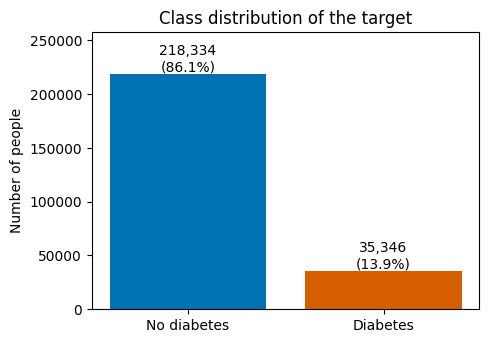

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(["No diabetes", "Diabetes"], counts.values, color=[BLUE, ORANGE])
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,}\n({share.values[i]:.1%})", ha="center", va="bottom")
ax.set_ylabel("Number of people")
ax.set_title("Class distribution of the target")
ax.set_ylim(0, counts.max() * 1.18)
save_and_show("eda01_class_distribution")

In [8]:
# What does 'diabetes = 1' mean here? Compare with the 3-class file (0 = none, 1 = prediabetes, 2 = diabetes).
three = pd.read_csv(OTHER_FILE)
print("Same number of rows in both files:", len(three) == len(df))
print("3-class counts:", three["Diabetes_012"].value_counts().sort_index().to_dict())
print("Binary target == (3-class target is 2) for every row:", bool((df["Diabetes_binary"].values == (three["Diabetes_012"].values == 2)).all()))

Same number of rows in both files: True
3-class counts: {0.0: 213703, 1.0: 4631, 2.0: 35346}
Binary target == (3-class target is 2) for every row: True


The check above shows what the binary label contains: it is 1 only for the people marked as diabetes in the 3-class file, so **prediabetes people are counted as "no diabetes"** in this binary file. The UCI page describes the label as "prediabetes or diabetes", which does not match the data. I will mention this in the limitations of the report.

**Imbalance:** about 14 out of every 100 people have diabetes. Accuracy will look high even for a useless model, so I will also use precision, recall, F1 and ROC-AUC, and I will try class weights.

## 5. Distributions of the numeric features

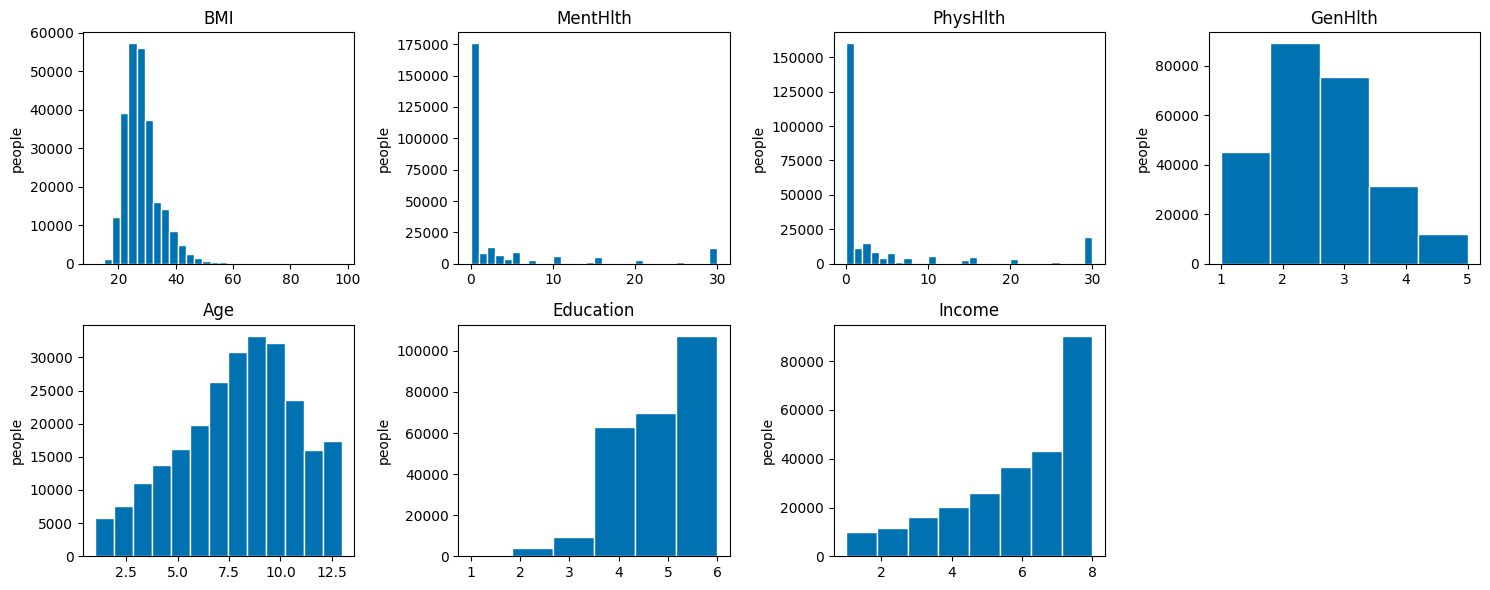

In [9]:
numeric_features = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), numeric_features):
    ax.hist(df[col], bins=min(30, df[col].nunique()), color=BLUE, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("people")
axes.ravel()[-1].axis("off")      # 7 plots on a 2x4 grid -> hide the empty one
plt.tight_layout()
save_and_show("eda02_numeric_distributions")

### Outliers in BMI
BMI is the only truly continuous measurement, so it is the main place where outliers can appear. I use the usual IQR rule (anything beyond 1.5 x IQR from the quartiles).

In [10]:
q1, q3 = df["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
low_limit, high_limit = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (df["BMI"] < low_limit) | (df["BMI"] > high_limit)
print(f"BMI range: {df['BMI'].min():.0f} to {df['BMI'].max():.0f} | median {df['BMI'].median():.0f}")
print(f"IQR rule limits: {low_limit:.1f} to {high_limit:.1f}")
print(f"BMI outliers: {is_outlier.sum():,} rows ({is_outlier.mean():.1%})")
print("Diabetes rate among BMI outliers:", f"{df.loc[is_outlier, 'Diabetes_binary'].mean():.1%}", "| among the rest:", f"{df.loc[~is_outlier, 'Diabetes_binary'].mean():.1%}")
print("BMI above 60:", (df["BMI"] > 60).sum(), "| BMI below 15:", (df["BMI"] < 15).sum())

BMI range: 12 to 98 | median 27
IQR rule limits: 13.5 to 41.5
BMI outliers: 9,847 rows (3.9%)
Diabetes rate among BMI outliers: 34.2% | among the rest: 13.1%
BMI above 60: 805 | BMI below 15: 68


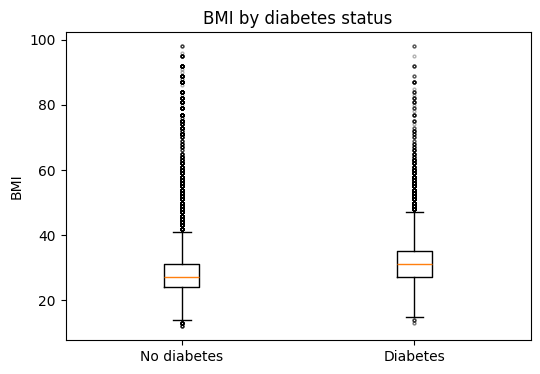

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([df.loc[df["Diabetes_binary"] == 0, "BMI"], df.loc[df["Diabetes_binary"] == 1, "BMI"]],
           tick_labels=["No diabetes", "Diabetes"], flierprops={"markersize": 2, "alpha": 0.3})
ax.set_ylabel("BMI")
ax.set_title("BMI by diabetes status")
save_and_show("eda03_bmi_boxplot")

Many BMI values above the IQR limit are real (very high BMI exists), so they are not automatically errors. I will decide in the preprocessing step whether to cap them rather than delete them.

## 6. Relationship between each feature and diabetes
These plots show **associations**, not causes. For example, people with high blood pressure having more diabetes does not prove that high blood pressure causes diabetes.

In [12]:
# Diabetes rate for people answering 0 vs 1 on each yes/no question
rows = []
for col in binary_cols:
    if col == "Diabetes_binary":
        continue
    rate_no = df.loc[df[col] == 0, "Diabetes_binary"].mean()
    rate_yes = df.loc[df[col] == 1, "Diabetes_binary"].mean()
    rows.append({"feature": col, "rate_if_0": rate_no, "rate_if_1": rate_yes, "difference": rate_yes - rate_no})
rate_table = pd.DataFrame(rows).sort_values("difference")
rate_table.round(3)

,feature,rate_if_0,rate_if_1,difference
6,PhysActivity,0.211,0.116,-0.095
9,HvyAlcoholConsump,0.144,0.058,-0.086
8,Veggies,0.180,0.130,-0.050
7,Fruits,0.158,0.129,-0.029
13,Sex,0.130,0.152,0.022
10,AnyHealthcare,0.115,0.141,0.026
11,NoDocbcCost,0.136,0.175,0.039
3,Smoker,0.121,0.163,0.042
2,CholCheck,0.025,0.144,0.118
1,HighChol,0.080,0.220,0.140


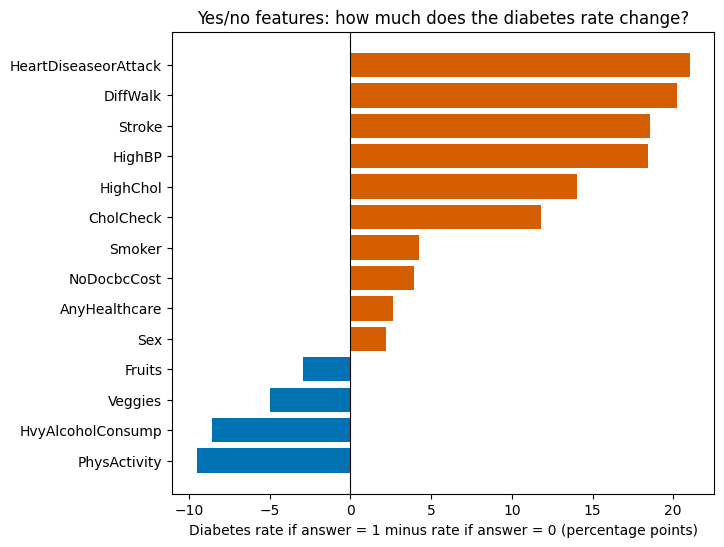

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = [ORANGE if d > 0 else BLUE for d in rate_table["difference"]]
ax.barh(rate_table["feature"], rate_table["difference"] * 100, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Diabetes rate if answer = 1 minus rate if answer = 0 (percentage points)")
ax.set_title("Yes/no features: how much does the diabetes rate change?")
save_and_show("eda04_binary_feature_effects")

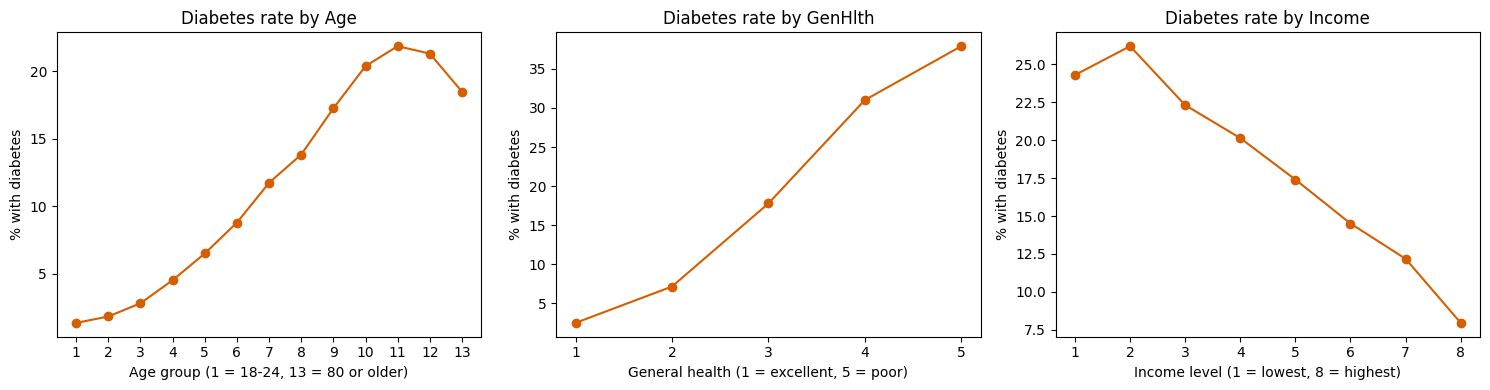

             people  diabetes_rate
BMI                               
underweight    3127          0.054
normal        68953          0.057
overweight    93749          0.114
obese         87851          0.234


In [14]:
# Diabetes rate by age group, general health and income (ordered features)
# One x-axis label per feature, because the meaning of "1" is different for each one
axis_labels = {"Age": "Age group (1 = 18-24, 13 = 80 or older)",
               "GenHlth": "General health (1 = excellent, 5 = poor)",
               "Income": "Income level (1 = lowest, 8 = highest)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "GenHlth", "Income"]):
    rate = df.groupby(col)["Diabetes_binary"].mean() * 100
    ax.plot(rate.index, rate.values, marker="o", color=ORANGE)
    ax.set_xticks(rate.index.astype(int))          # whole numbers only, these are categories
    ax.set_xlabel(axis_labels[col])
    ax.set_ylabel("% with diabetes")
    ax.set_title(f"Diabetes rate by {col}")
plt.tight_layout()
save_and_show("eda05_rate_by_ordered_features")

# BMI categories from the WHO cut-offs
bmi_groups = pd.cut(df["BMI"], [0, 18.5, 25, 30, 100], labels=["underweight", "normal", "overweight", "obese"], right=False)
print(df.groupby(bmi_groups, observed=True)["Diabetes_binary"].agg(people="size", diabetes_rate="mean").round(3))

## 7. Correlations
Pearson correlation between every feature and the target. Because most columns are 0/1 or ordered codes, this is only a rough guide. It also only catches straight-line relationships.

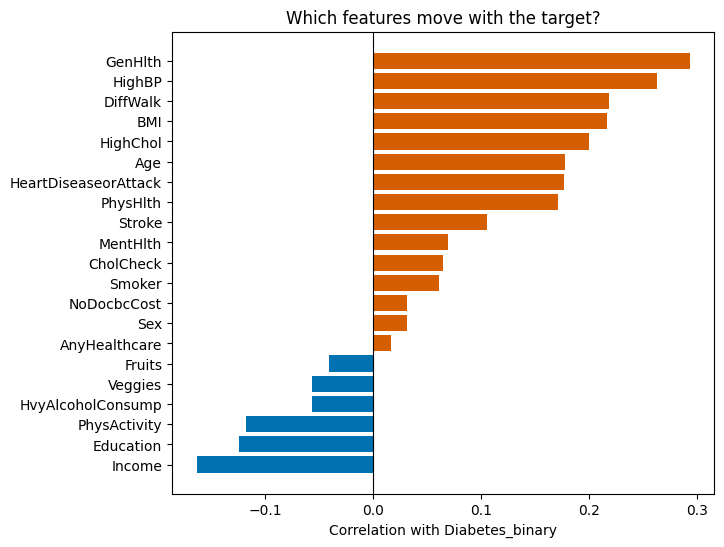

Income                 -0.164
Education              -0.124
PhysActivity           -0.118
HvyAlcoholConsump      -0.057
Veggies                -0.057
Fruits                 -0.041
AnyHealthcare           0.016
Sex                     0.031
NoDocbcCost             0.031
Smoker                  0.061
CholCheck               0.065
MentHlth                0.069
Stroke                  0.106
PhysHlth                0.171
HeartDiseaseorAttack    0.177
Age                     0.177
HighChol                0.200
BMI                     0.217
DiffWalk                0.218
HighBP                  0.263
GenHlth                 0.294


In [15]:
corr_with_target = df.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr_with_target.index, corr_with_target.values, color=[ORANGE if v > 0 else BLUE for v in corr_with_target.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with Diabetes_binary")
ax.set_title("Which features move with the target?")
save_and_show("eda06_target_correlation")
print(corr_with_target.round(3).to_string())

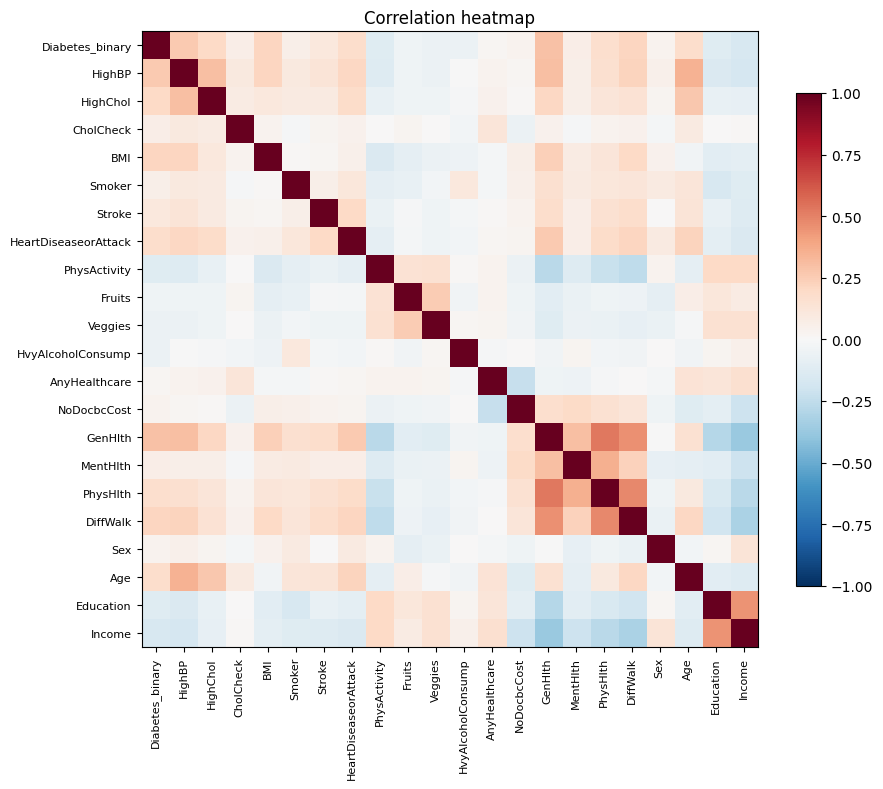

Strongest feature-to-feature correlations:
GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income     -0.370


In [16]:
# Correlation heatmap of all columns (looking for features that carry similar information)
corr = df.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap")
save_and_show("eda07_correlation_heatmap")

# Pairs of features that are strongly related to each other (not counting the target)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.drop(labels=[i for i in pairs.index if "Diabetes_binary" in i])
print("Strongest feature-to-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

## 8. EDA summary

**Facts from the output above** (checked against the cells):
- The raw file has 253,680 rows and 22 columns, so it meets the 20,000-row requirement. There are no missing values.
- Only about 14% of people have diabetes, so the classes are strongly imbalanced.
- The binary target does not include prediabetes (those people are labelled 0).
- There are 24,206 exact duplicate rows. With only yes/no style answers this is expected, but it needs a decision before splitting the data.
- BMI is the only continuous feature and it has a long right tail.

**My interpretation (to write in my own words before moving on):**
1. Which features seem most related to diabetes, and does that match what I know about the disease?
2. What problems will the imbalance cause for the models, and what will I do about it?
3. What preprocessing decisions follow from this EDA (duplicates, BMI outliers, scaling, feature ideas)?

---
# Step 3: Preprocessing and feature engineering

The EDA gave me things to deal with. This table lists each problem, what I decided and why.

| Problem found in the EDA | Decision | Why |
|---|---|---|
| 24,206 exact duplicate rows | Remove them **before** splitting | An identical row in train and test would let a model "remember" the answer and make the test score look better than it is |
| No missing values | Check again with an assertion, no imputation | Nothing to fill in |
| BMI has a long right tail (max 98) | Cap at the 1st and 99th percentile (learned from training data only) | Keeps the rows, stops a few extreme values from dominating scaling and the neural network |
| Columns on very different scales (BMI ~28, days 0-30, codes 1-13) | `StandardScaler` fitted on the training set only | Needed for logistic regression and the neural network; fitting on training data only avoids leakage |
| Yes/no columns are already 0/1, ordered columns are already numbers | No one-hot encoding | Nothing to encode. Age, Education, Income and GenHlth keep their order |
| Only 13.9% positives | Class weights now, SMOTE later as an experiment | Weights need no new data. SMOTE changes the training data, so I will test it on its own and only on the training set |
| Ideas for extra features | BMI category, lifestyle risk score, condition count, poor-health days | Test later whether they help |

## 9. Set up the helper functions

In [17]:
import sys
import joblib

# The reusable code lives in src/preprocessing.py so every experiment uses the same steps.
sys.path.insert(0, str(ROOT / "src"))
from preprocessing import (TARGET, BINARY_COLUMNS, ORDINAL_COLUMNS, ENGINEERED_COLUMNS, load_data, remove_duplicates,
                           add_features, split_data, build_preprocessor, transform_to_frame, ToDataFrame)

MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

raw_df = load_data(DATA_FILE)
print("Raw data:", raw_df.shape)

Raw data: (253680, 22)


## 10. Missing values and duplicates

In [18]:
# 1) Missing values: none in the EDA, so I only check that this is still true.
assert raw_df.isna().sum().sum() == 0, "There are missing values, an imputation step is needed"
print("Missing values: 0 -> nothing to impute")

# 2) Duplicates. First look at a more serious problem: identical ANSWERS with a different label.
feature_cols = [c for c in raw_df.columns if c != TARGET]
labels_per_profile = raw_df.groupby(feature_cols)[TARGET].nunique()
print("Answer profiles that appear with BOTH labels (0 and 1):", int((labels_per_profile > 1).sum()))

# 3) Remove exact duplicate rows and check what changes.
df_clean, n_removed = remove_duplicates(raw_df)
print(f"Rows removed: {n_removed:,} | rows left: {len(df_clean):,}")
print(f"Diabetes share before: {raw_df[TARGET].mean():.3%} | after: {df_clean[TARGET].mean():.3%}")

Missing values: 0 -> nothing to impute
Answer profiles that appear with BOTH labels (0 and 1): 1566


Rows removed: 24,206 | rows left: 229,474
Diabetes share before: 13.933% | after: 15.295%


Removing duplicates changes the diabetes share a little (see the numbers above), so I will report results on the cleaned data and say so in the report. The rows that share the same answers but have different labels are **not** exact duplicates. They stay, because two people can answer the same way and still differ in diabetes status. This is label noise that limits how accurate any model can be, and a small number of test rows will share their answers with a training row of the opposite label (counted in section 13).

## 11. Outliers: cap extreme BMI values
The cap limits are learned from the **training** set inside the pipeline (section 15). Here I only look at what the limits would be on the full cleaned data, to understand their effect.

In [19]:
low, high = df_clean["BMI"].quantile([0.01, 0.99])
n_capped = ((df_clean["BMI"] < low) | (df_clean["BMI"] > high)).sum()
print(f"1st and 99th percentile of BMI: {low:.0f} and {high:.0f}")
print(f"Values that would be capped: {n_capped:,} ({n_capped / len(df_clean):.1%} of rows). No rows are deleted.")
print(f"Largest BMI before capping: {df_clean['BMI'].max():.0f} -> after capping: {high:.0f}")

1st and 99th percentile of BMI: 18 and 50
Values that would be capped: 3,484 (1.5% of rows). No rows are deleted.
Largest BMI before capping: 98 -> after capping: 50


## 12. Feature engineering
Four new columns (defined in `src/preprocessing.py`):

| New feature | How it is built | Why |
|---|---|---|
| `bmi_category` | WHO groups: 0 under, 1 normal, 2 over, 3 obese | The EDA showed diabetes rates jump between BMI groups, not smoothly |
| `lifestyle_risk_score` | smoker + no physical activity + no fruit + no vegetables (0 to 4) | Combines several weak habit signals into one |
| `condition_count` | high BP + high cholesterol + stroke + heart disease + difficulty walking (0 to 5) | Several conditions together may matter more than each alone |
| `poor_health_days` | MentHlth + PhysHlth (0 to 60) | One simple measure of how unwell the person feels |

A feature is only useful if it helps the models, so in the experiments (Steps 4 to 6) I will compare models **with** and **without** them. Here I only check that they show a sensible pattern.

In [20]:
df_feat = add_features(df_clean)
df_feat[["BMI", "bmi_category", "lifestyle_risk_score", "condition_count", "poor_health_days"]].head()

,BMI,bmi_category,lifestyle_risk_score,condition_count,poor_health_days
0,40.0,3,3.0,3.0,33.0
1,25.0,2,3.0,0.0,0.0
2,28.0,2,2.0,3.0,60.0
3,27.0,2,0.0,1.0,0.0
4,24.0,1,0.0,2.0,3.0


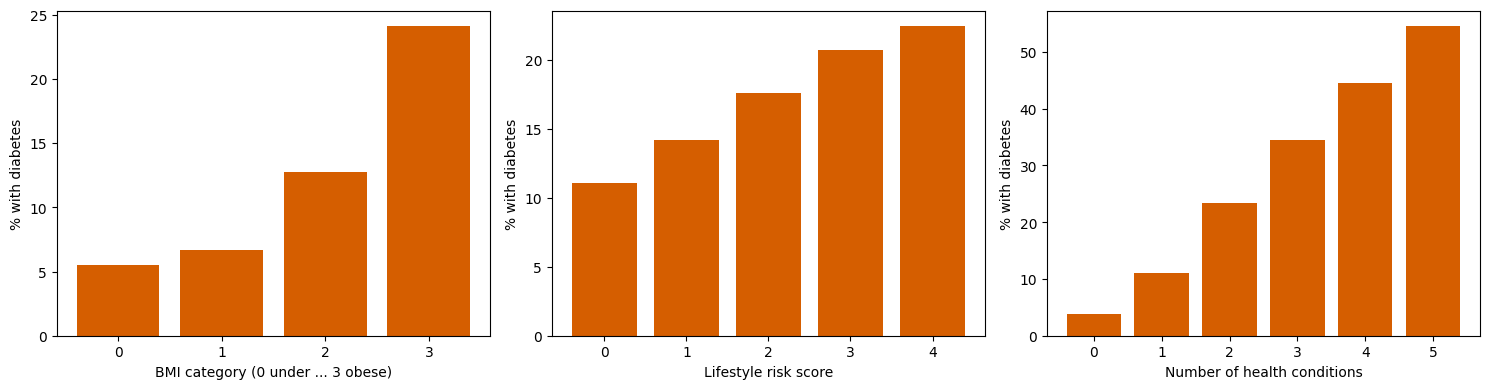

Correlation with the target:
bmi_category            0.194
lifestyle_risk_score    0.091
condition_count         0.327
poor_health_days        0.133
BMI                     0.205
GenHlth                 0.277
HighBP                  0.254


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in [(axes[0], "bmi_category", "BMI category (0 under ... 3 obese)"),
                       (axes[1], "lifestyle_risk_score", "Lifestyle risk score"),
                       (axes[2], "condition_count", "Number of health conditions")]:
    rate = df_feat.groupby(col)[TARGET].mean() * 100
    ax.bar(rate.index.astype(int).astype(str), rate.values, color=ORANGE)
    ax.set_xlabel(title)
    ax.set_ylabel("% with diabetes")
plt.tight_layout()
save_and_show("fe01_engineered_feature_rates")

new_cols = ["bmi_category", "lifestyle_risk_score", "condition_count", "poor_health_days"]
print("Correlation with the target:")
print(df_feat[new_cols + ["BMI", "GenHlth", "HighBP"]].corrwith(df_feat[TARGET]).round(3).to_string())

The diabetes rate rises with `condition_count` and with `bmi_category`, which is the pattern I expected. The correlations above show whether the new columns are at least as informative as the originals they are built from. The real test is whether they improve the models, which I do in the experiments.

## 13. Train / validation / test split
70% train, 15% validation, 15% test, **stratified** by the target so each part has the same diabetes share. The seed is fixed. The validation set is for tuning and early stopping, and the **test set is only used at the end**.

In [22]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df_feat)

sizes = pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_test)],
                      "diabetes share": [y_train.mean(), y_val.mean(), y_test.mean()]},
                     index=["train", "validation", "test"])
sizes["diabetes share"] = sizes["diabetes share"].round(4)
print(sizes)

# Leakage check 1: no complete row (answers AND label) may appear in two parts.
# Duplicates were removed before the split, so this must be zero.
def full_rows(X, y):
    return set(map(tuple, np.column_stack([X.values, y.values])))

train_full = full_rows(X_train, y_train)
print("Complete rows of validation found in train:", len(train_full & full_rows(X_val, y_val)))
print("Complete rows of test found in train      :", len(train_full & full_rows(X_test, y_test)))
assert not (train_full & full_rows(X_val, y_val)) and not (train_full & full_rows(X_test, y_test))

# Check 2 (information only): test people whose ANSWERS also occur in train, but with the opposite label.
# These are the "same answers, different outcome" profiles found earlier. They are label noise, not leakage.
train_answers = set(map(tuple, X_train.values))
noisy_test = sum(tuple(r) in train_answers for r in X_test.values)
print(f"Test rows with the same answers as a training row (opposite label): {noisy_test} ({noisy_test / len(X_test):.2%})")

              rows  diabetes share
train       160631          0.1529
validation   34421          0.1529
test         34422          0.1530


Complete rows of validation found in train: 0
Complete rows of test found in train      : 0


Test rows with the same answers as a training row (opposite label): 326 (0.95%)


## 14. Class imbalance
The positive class (diabetes) is only about 15% of the cleaned data. Plan:
1. **Class weights** (used in the sections that follow): each diabetes example counts more in the loss, so the model cannot win by ignoring them.
2. **SMOTE** (an experiment later): creates artificial diabetes examples. It is applied **only to the training set**, never to validation or test, and I will document how it changes the results.

In [23]:
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
print(f"Training set: {n_neg:,} without diabetes, {n_pos:,} with diabetes (ratio {n_neg / n_pos:.1f} to 1)")
print("Class weights (balanced):", {k: round(float(v), 3) for k, v in class_weight.items()})

Training set: 136,063 without diabetes, 24,568 with diabetes (ratio 5.5 to 1)
Class weights (balanced): {0: 0.59, 1: 3.269}


## 15. Build, fit and apply the preprocessing pipeline
The pipeline is **fitted on the training set only** (it learns the BMI caps and the means and standard deviations there). Then the same fitted pipeline transforms the validation and test sets. If I fitted it on all the data, information from the test set would leak into training.

In [24]:
preprocessor = build_preprocessor(use_engineered=True)
preprocessor.fit(X_train)                      # learns BMI limits, means and standard deviations from TRAIN only

train_scaled = transform_to_frame(preprocessor, X_train)
val_scaled = transform_to_frame(preprocessor, X_val)
test_scaled = transform_to_frame(preprocessor, X_test)

bmi_cap = preprocessor.named_transformers_["bmi"].named_steps["cap"]
print(f"BMI caps learned from the training set: {bmi_cap.low_[0]:.0f} to {bmi_cap.high_[0]:.0f}")
print("Final feature count:", train_scaled.shape[1], "(14 yes/no + BMI + 6 ordered + 4 engineered)")
print()
print("Mean and standard deviation of a few scaled columns:")
check = pd.DataFrame({"train mean": train_scaled[["BMI", "Age", "Income"]].mean(),
                      "train std": train_scaled[["BMI", "Age", "Income"]].std(),
                      "val mean": val_scaled[["BMI", "Age", "Income"]].mean(),
                      "test mean": test_scaled[["BMI", "Age", "Income"]].mean()}).round(3)
print(check)

BMI caps learned from the training set: 18 to 50
Final feature count: 25 (14 yes/no + BMI + 6 ordered + 4 engineered)

Mean and standard deviation of a few scaled columns:
        train mean  train std  val mean  test mean
BMI           -0.0        1.0     0.016      0.004
Age            0.0        1.0    -0.007      0.012
Income        -0.0        1.0    -0.004     -0.011


The training columns have mean 0 and standard deviation 1 (the scaler was fitted there). The validation and test columns are close to, but not exactly, 0. This is correct: they were scaled with numbers learned from the training data.

In [25]:
# Final sanity checks before modelling
assert not train_scaled.isna().any().any() and not val_scaled.isna().any().any() and not test_scaled.isna().any().any()
assert list(train_scaled.columns) == list(val_scaled.columns) == list(test_scaled.columns)
print("No missing values after preprocessing, and the columns are the same in all three sets.")
print("Shapes:", train_scaled.shape, val_scaled.shape, test_scaled.shape)

# Save the fitted pipeline so the exact same transformation can be reused later.
joblib.dump(preprocessor, MODELS / "preprocessor.joblib")
print("Saved the preprocessing pipeline to models/preprocessor.joblib")

No missing values after preprocessing, and the columns are the same in all three sets.
Shapes: (160631, 25) (34421, 25) (34422, 25)
Saved the preprocessing pipeline to models/preprocessor.joblib


## 16. Step 3 summary

**Facts from the output above:**
- The duplicates were removed before splitting, and no complete row (answers and label) appears in more than one of train, validation and test. A small share of test rows have the same answers as a training row with the opposite label; this is label noise that stays in the data.
- There is nothing to impute, and no categorical encoding was needed.
- BMI outliers are capped (the limits come from the training set), not deleted.
- The pipeline is fitted on the training set only. It outputs 25 features: 14 yes/no, BMI, 6 ordered columns and 4 engineered ones.
- The diabetes share is the same in the train, validation and test sets (stratified split, seed 42).

**To write in my own words before the report:**
1. Why did I remove duplicates before the split and not after?
2. Why is the scaler fitted on the training set only? What would go wrong if I fitted it on everything?
3. Which of the four new features do I expect to help, and why? (I will check this in the experiments.)

---
# Step 4: Traditional machine learning (scikit-learn)

**Plan.** Train several classic models, compare them in a fair way, tune the promising ones and test a few ideas (new features, class imbalance). Every run is recorded so the experiment table in the report can be traced back to real runs.

| Model | Why I chose it | Expected weakness |
|---|---|---|
| Dummy (always predicts the majority class) | Baseline: any real model must beat it | Learns nothing |
| Logistic regression | Simple, fast, easy to explain (one weight per feature) | Can only draw straight-line boundaries |
| Random forest | Many decision trees voting; handles non-linear patterns | Bigger and slower, harder to explain |
| Gradient boosting (`HistGradientBoosting`) | Trees built one after another, each fixing the mistakes of the last; usually strong on tables | More settings to tune, can overfit if it runs too long |
| SVM (RBF kernel) | Flexible curved boundary | Training time grows very fast with rows, so I use a **20,000-row sample** of the training set (the validation set stays complete) |

**Fair comparison rules**
- Every model trains on the same **training set** and is scored on the same **validation set**. The **test set is not touched** until the final evaluation.
- Metrics: accuracy, precision, recall, F1 (all for the diabetes class), ROC-AUC and PR-AUC. Accuracy alone is misleading here, because always answering "no diabetes" is already about 85% accurate. Precision and recall use the usual cut-off of 0.5.
- I compare models mainly with **ROC-AUC** (it does not depend on the cut-off), and I also look at PR-AUC and F1, which matter more when the positive class is rare.

**How the runs are tracked** (code in `src/tracking.py`)
1. `reports/experiment_log.csv`: the experiment table (model, settings, data split, metrics, time, observations).
2. `logs/step4_traditional_ml.log`: plain text log.
3. `logs/tensorboard/`: one TensorBoard run per experiment, plus curves. View them with `tensorboard --logdir logs/tensorboard` and open http://localhost:6006 (the **HParams** tab compares runs, the **Scalars** tab shows the curves).

## 17. Setup: imports, tracker and one helper that runs and records an experiment

In [26]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, learning_curve, train_test_split
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, log_loss, roc_auc_score
from imblearn.over_sampling import SMOTE

from tracking import ExperimentTracker, evaluate_binary

LOGS = ROOT / "logs"
REPORTS = ROOT / "reports"
tracker = ExperimentTracker(REPORTS / "experiment_log.csv", LOGS / "tensorboard", LOGS / "step4_traditional_ml.log")

SPLIT_TEXT = (f"stratified 70/15/15, seed {SEED}, duplicates removed "
              f"(train {len(X_train):,} / val {len(X_val):,} / test {len(X_test):,})")
FEATURES_ALL = "25 features (21 original + 4 engineered)"
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)    # used for tuning, on the training set only

results = {}        # exp_id -> fitted model, scores and preprocessor (used later for plots and saving)

def run_experiment(exp_id, model_name, model, params, X_tr, y_tr, X_ev, y_ev, features,
                   prep=preprocessor, use_decision_function=False):
    # Fit the model, score it on the evaluation set, and record everything with the tracker.
    start = time.time()
    model.fit(X_tr, y_tr)
    seconds = time.time() - start

    if use_decision_function:                      # SVC without probabilities: use its distance score
        score, pred = model.decision_function(X_ev), model.predict(X_ev)
    else:
        score = model.predict_proba(X_ev)[:, 1]
        pred = (score >= 0.5).astype(int)
    metrics = evaluate_binary(y_ev, score, pred)

    tracker.log_experiment(exp_id, "4 traditional ML", model_name, params, features, SPLIT_TEXT,
                           f"validation ({len(y_ev):,} rows)", metrics, seconds)
    results[exp_id] = {"name": model_name, "model": model, "prep": prep, "score": score, "pred": pred, "metrics": metrics}
    return metrics

def show_results(ids):
    # Small table of metrics for some experiments
    rows = [{"exp": i, "model": results[i]["name"], **{k: round(v, 3) for k, v in results[i]["metrics"].items()}} for i in ids]
    return pd.DataFrame(rows).set_index("exp")

## 18. Baseline: the model that never predicts diabetes
Any useful model has to beat this. It shows why accuracy alone cannot be trusted here.

In [27]:
run_experiment("T01", "Dummy baseline", DummyClassifier(strategy="most_frequent"), {"strategy": "most_frequent"},
               train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)
show_results(["T01"])

18:07:59 | T01 | Dummy baseline | acc 0.847 | precision 0.000 | recall 0.000 | F1 0.000 | ROC-AUC 0.500 | PR-AUC 0.153 | 0.0s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,
T01,Dummy baseline,0.847,0.0,0.0,0.0,0.5,0.153


The baseline gets high accuracy but has **zero recall and zero F1** for diabetes, and its ROC-AUC is 0.5 (no better than guessing). So accuracy would hide a useless model, and I will judge models with the other metrics.

## 19. First round: four models with sensible default settings
Logistic regression, random forest and gradient boosting use `class_weight="balanced"` (the weights from Step 3), so the rare diabetes class counts more. The SVM trains on a 20,000-row stratified sample of the training set.

In [28]:
# T02: logistic regression, default regularisation
run_experiment("T02", "Logistic regression", LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=SEED),
               {"C": 1.0, "class_weight": "balanced"}, train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

# T03: random forest, 200 trees, no depth limit
run_experiment("T03", "Random forest", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
               {"n_estimators": 200, "max_depth": "None", "class_weight": "balanced_subsample"}, train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

# T04: gradient boosting with default settings
run_experiment("T04", "Gradient boosting", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
               {"learning_rate": 0.1, "max_leaf_nodes": 31, "class_weight": "balanced"}, train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

# T05: SVM on a 20,000-row sample of the training set (the full set would take too long)
svm_X, _, svm_y, _ = train_test_split(train_scaled, y_train, train_size=20000, stratify=y_train, random_state=SEED)
run_experiment("T05", "SVM (RBF)", SVC(kernel="rbf", C=1.0, class_weight="balanced"),
               {"C": 1.0, "kernel": "rbf", "class_weight": "balanced", "train_rows": 20000},
               svm_X, svm_y, val_scaled, y_val, FEATURES_ALL + ", trained on 20,000-row sample", use_decision_function=True)

show_results(["T01", "T02", "T03", "T04", "T05"])

18:07:59 | T02 | Logistic regression | acc 0.719 | precision 0.323 | recall 0.766 | F1 0.455 | ROC-AUC 0.815 | PR-AUC 0.430 | 0.4s


18:08:10 | T03 | Random forest | acc 0.843 | precision 0.461 | recall 0.156 | F1 0.233 | ROC-AUC 0.779 | PR-AUC 0.358 | 9.8s


18:08:12 | T04 | Gradient boosting | acc 0.710 | precision 0.320 | recall 0.796 | F1 0.457 | ROC-AUC 0.820 | PR-AUC 0.445 | 2.4s


18:09:10 | T05 | SVM (RBF) | acc 0.712 | precision 0.317 | recall 0.766 | F1 0.449 | ROC-AUC 0.799 | PR-AUC 0.371 | 10.2s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,
T01,Dummy baseline,0.847,0.000,0.000,0.000,0.500,0.153
T02,Logistic regression,0.719,0.323,0.766,0.455,0.815,0.430
T03,Random forest,0.843,0.461,0.156,0.233,0.779,0.358
T04,Gradient boosting,0.710,0.320,0.796,0.457,0.820,0.445
T05,SVM (RBF),0.712,0.317,0.766,0.449,0.799,0.371


## 20. How do the models change as they grow?
Two curves, also written to TensorBoard (Scalars tab, runs `curve_*`):
- **Gradient boosting:** validation and training loss after each boosting round. If the training loss keeps falling while the validation loss starts rising, the model is overfitting.
- **Random forest:** validation ROC-AUC as more trees are added.

18:09:18 | curve logged to TensorBoard run 'curve_gradient_boosting': train_loss, val_loss, val_roc_auc


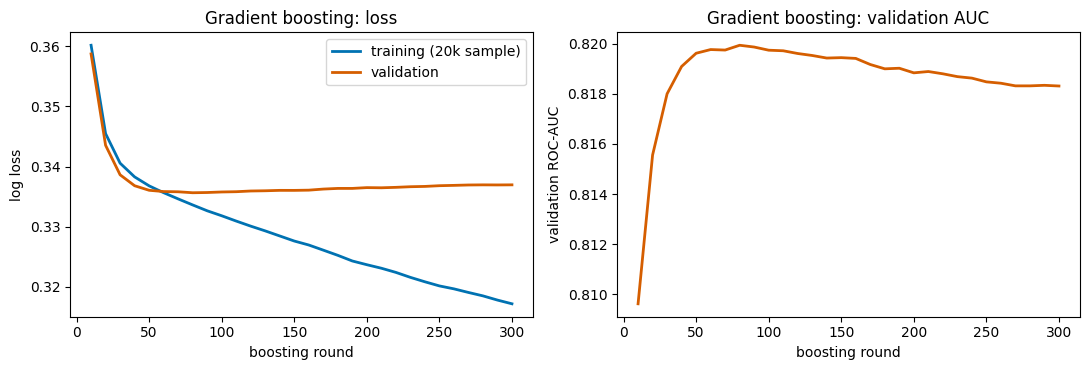

Best validation AUC 0.8199 at round 80; lowest validation loss at round 80


In [29]:
# Boosting curve: a model that keeps all 300 rounds (no early stopping), so the whole curve can be seen.
# No class weights here: weights shift the predicted probabilities, which would distort the log loss.
curve_model = HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=31, max_iter=300, early_stopping=False,
                                             class_weight=None, random_state=SEED).fit(train_scaled, y_train)

# Training loss is measured on a 20,000-row sample of the training set, to keep it fast.
sample = np.random.RandomState(SEED).choice(len(train_scaled), 20000, replace=False)
tr_sample, y_tr_sample = train_scaled.iloc[sample], y_train.iloc[sample]

rounds, train_loss, val_loss, val_auc = [], [], [], []
for i, (p_tr, p_val) in enumerate(zip(curve_model.staged_predict_proba(tr_sample),
                                      curve_model.staged_predict_proba(val_scaled)), start=1):
    if i % 10 == 0:
        rounds.append(i)
        train_loss.append(log_loss(y_tr_sample, p_tr[:, 1]))
        val_loss.append(log_loss(y_val, p_val[:, 1]))
        val_auc.append(roc_auc_score(y_val, p_val[:, 1]))

tracker.log_curve("curve_gradient_boosting", {"train_loss": train_loss, "val_loss": val_loss, "val_roc_auc": val_auc}, rounds)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(rounds, train_loss, color=BLUE, lw=2, label="training (20k sample)")
ax[0].plot(rounds, val_loss, color=ORANGE, lw=2, label="validation")
ax[0].set_xlabel("boosting round"); ax[0].set_ylabel("log loss"); ax[0].set_title("Gradient boosting: loss"); ax[0].legend()
ax[1].plot(rounds, val_auc, color=ORANGE, lw=2)
ax[1].set_xlabel("boosting round"); ax[1].set_ylabel("validation ROC-AUC"); ax[1].set_title("Gradient boosting: validation AUC")
plt.tight_layout()
save_and_show("ml01_boosting_curve")
print(f"Best validation AUC {max(val_auc):.4f} at round {rounds[int(np.argmax(val_auc))]}; lowest validation loss at round {rounds[int(np.argmin(val_loss))]}")

18:09:21 | curve logged to TensorBoard run 'curve_random_forest': val_roc_auc


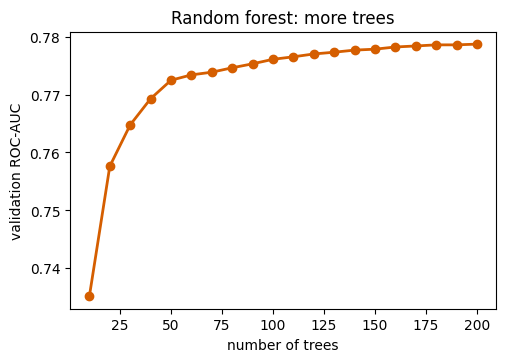

AUC with 10 trees: 0.7351 | with 100 trees: 0.7761 | with 200 trees: 0.7788


In [30]:
# Random forest curve: average the first k trees only (the forest from experiment T03).
rf_trees = results["T03"]["model"].estimators_
tree_probs = np.array([t.predict_proba(val_scaled.values)[:, 1] for t in rf_trees])
counts = list(range(10, 201, 10))
rf_auc = [roc_auc_score(y_val, tree_probs[:k].mean(axis=0)) for k in counts]
tracker.log_curve("curve_random_forest", {"val_roc_auc": rf_auc}, counts)

plt.figure(figsize=(5.5, 3.6))
plt.plot(counts, rf_auc, color=ORANGE, lw=2, marker="o")
plt.xlabel("number of trees"); plt.ylabel("validation ROC-AUC"); plt.title("Random forest: more trees")
save_and_show("ml02_rf_tree_curve")
print(f"AUC with 10 trees: {rf_auc[0]:.4f} | with 100 trees: {rf_auc[9]:.4f} | with 200 trees: {rf_auc[-1]:.4f}")

## 21. Hyperparameter tuning
Tuning uses **3-fold cross-validation on the training set only**; the validation set is kept for comparing the final models. The metric is ROC-AUC. A grid is used for logistic regression (small) and random search for the forest and boosting (many combinations).

In [31]:
# --- Logistic regression: grid over regularisation strength C and class weighting ---
lr_search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=SEED),
                         {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
                         scoring="roc_auc", cv=CV, n_jobs=-1)
lr_search.fit(train_scaled, y_train)
print("Logistic regression best:", lr_search.best_params_, "| CV ROC-AUC", round(lr_search.best_score_, 4))

# All grid results go to TensorBoard so the effect of C can be seen (step = position in the grid)
grid = pd.DataFrame(lr_search.cv_results_)[["param_C", "param_class_weight", "mean_test_score"]]
print(grid.round(4).to_string(index=False))
tracker.log_curve("curve_logreg_grid", {"cv_roc_auc": grid["mean_test_score"].values}, range(len(grid)))

run_experiment("T06", "Logistic regression (tuned)", clone(lr_search.best_estimator_),
               {**lr_search.best_params_, "cv_roc_auc": round(lr_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

18:09:30 | curve logged to TensorBoard run 'curve_logreg_grid': cv_roc_auc


Logistic regression best: {'C': 0.1, 'class_weight': 'balanced'} | CV ROC-AUC 0.8086
 param_C param_class_weight  mean_test_score
    0.01               None           0.8084
    0.01           balanced           0.8086
    0.10               None           0.8086
    0.10           balanced           0.8086
    1.00               None           0.8085
    1.00           balanced           0.8086
   10.00               None           0.8085
   10.00           balanced           0.8086


18:09:31 | T06 | Logistic regression (tuned) | acc 0.719 | precision 0.323 | recall 0.766 | F1 0.454 | ROC-AUC 0.815 | PR-AUC 0.431 | 0.4s


{'accuracy': 0.7188925365329305,
 'precision': 0.32312379730596535,
 'recall': 0.7655775075987842,
 'f1': 0.4544429409111412,
 'roc_auc': np.float64(0.814946703221726),
 'pr_auc': np.float64(0.4305073990701189)}

In [32]:
# --- Random forest: random search (8 combinations x 3 folds) ---
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    {"max_depth": [8, 12, 16, None], "min_samples_leaf": [1, 5, 20, 50], "max_features": ["sqrt", 0.5]},
    n_iter=8, scoring="roc_auc", cv=CV, random_state=SEED, n_jobs=1)
rf_search.fit(train_scaled, y_train)
print("Random forest best:", rf_search.best_params_, "| CV ROC-AUC", round(rf_search.best_score_, 4))

run_experiment("T07", "Random forest (tuned)", clone(rf_search.best_estimator_),
               {**rf_search.best_params_, "n_estimators": 200, "class_weight": "balanced_subsample", "cv_roc_auc": round(rf_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

Random forest best: {'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 12} | CV ROC-AUC 0.8109


18:13:03 | T07 | Random forest (tuned) | acc 0.724 | precision 0.328 | recall 0.767 | F1 0.460 | ROC-AUC 0.817 | PR-AUC 0.442 | 13.1s


{'accuracy': 0.7240928502948781,
 'precision': 0.3280805783445699,
 'recall': 0.7672872340425532,
 'f1': 0.45963015647226174,
 'roc_auc': np.float64(0.8170261592387424),
 'pr_auc': np.float64(0.4423163665589949)}

In [33]:
# --- Gradient boosting: random search (10 combinations x 3 folds), early stopping inside each fit ---
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, early_stopping=True, n_iter_no_change=15, random_state=SEED),
    {"learning_rate": [0.03, 0.05, 0.1, 0.2], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50, 100],
     "l2_regularization": [0, 0.1, 1, 10]},
    n_iter=10, scoring="roc_auc", cv=CV, random_state=SEED, n_jobs=-1)
hgb_search.fit(train_scaled, y_train)
print("Gradient boosting best:", hgb_search.best_params_, "| CV ROC-AUC", round(hgb_search.best_score_, 4))

run_experiment("T08", "Gradient boosting (tuned)", clone(hgb_search.best_estimator_),
               {**hgb_search.best_params_, "class_weight": "balanced", "cv_roc_auc": round(hgb_search.best_score_, 4)},
               train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)
show_results(["T01", "T02", "T03", "T04", "T05", "T06", "T07", "T08"])

Gradient boosting best: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.05, 'l2_regularization': 10} | CV ROC-AUC 0.8143


18:13:38 | T08 | Gradient boosting (tuned) | acc 0.708 | precision 0.318 | recall 0.792 | F1 0.454 | ROC-AUC 0.820 | PR-AUC 0.446 | 3.4s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,
T01,Dummy baseline,0.847,0.000,0.000,0.000,0.500,0.153
T02,Logistic regression,0.719,0.323,0.766,0.455,0.815,0.430
T03,Random forest,0.843,0.461,0.156,0.233,0.779,0.358
T04,Gradient boosting,0.710,0.320,0.796,0.457,0.820,0.445
T05,SVM (RBF),0.712,0.317,0.766,0.449,0.799,0.371
T06,Logistic regression (tuned),0.719,0.323,0.766,0.454,0.815,0.431
T07,Random forest (tuned),0.724,0.328,0.767,0.460,0.817,0.442
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446


## 22. Do the engineered features help?
Same tuned gradient boosting model (T08), but trained on the 21 original features only. The only change is the feature set, so any difference comes from the four new columns.

In [34]:
prep_original = build_preprocessor(use_engineered=False).fit(X_train)       # fitted on train only, like before
train_orig = transform_to_frame(prep_original, X_train)
val_orig = transform_to_frame(prep_original, X_val)
print("Features without engineered columns:", train_orig.shape[1])

run_experiment("T09", "Gradient boosting (tuned), no engineered features", clone(hgb_search.best_estimator_),
               {**hgb_search.best_params_, "class_weight": "balanced"},
               train_orig, y_train, val_orig, y_val, "21 original features", prep=prep_original)
show_results(["T08", "T09"])

Features without engineered columns: 21


18:13:42 | T09 | Gradient boosting (tuned), no engineered features | acc 0.708 | precision 0.318 | recall 0.794 | F1 0.454 | ROC-AUC 0.819 | PR-AUC 0.446 | 3.1s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446
T09,"Gradient boosting (tuned), no engineered features",0.708,0.318,0.794,0.454,0.819,0.446


## 23. Class imbalance: three ways to handle it
All three use the same tuned gradient boosting model.
- **T08 (class weights)**: already done above.
- **T10 (nothing)**: no class weights, to see what happens without help.
- **T11 (SMOTE)**: artificial diabetes examples are created in the **training set only** (the validation set is left as it is). SMOTE creates new points between neighbours, so yes/no columns can get in-between values like 0.37. That is a known weakness when most features are binary.

In [35]:
# T10: no class weights at all
run_experiment("T10", "Gradient boosting (tuned), no class weights", clone(hgb_search.best_estimator_).set_params(class_weight=None),
               {**hgb_search.best_params_, "class_weight": "None"}, train_scaled, y_train, val_scaled, y_val, FEATURES_ALL)

# T11: SMOTE on the training set, no class weights
smote = SMOTE(random_state=SEED)
train_smote, y_train_smote = smote.fit_resample(train_scaled, y_train)
print(f"Training rows before SMOTE: {len(y_train):,} (diabetes {y_train.mean():.1%}) | after: {len(y_train_smote):,} (diabetes {y_train_smote.mean():.1%})")
run_experiment("T11", "Gradient boosting (tuned) + SMOTE", clone(hgb_search.best_estimator_).set_params(class_weight=None),
               {**hgb_search.best_params_, "class_weight": "None", "smote_train_rows": len(y_train_smote)},
               train_smote, y_train_smote, val_scaled, y_val, FEATURES_ALL + ", SMOTE on train")
show_results(["T08", "T10", "T11"])

18:13:47 | T10 | Gradient boosting (tuned), no class weights | acc 0.855 | precision 0.584 | recall 0.171 | F1 0.264 | ROC-AUC 0.820 | PR-AUC 0.445 | 4.4s


Training rows before SMOTE: 160,631 (diabetes 15.3%) | after: 272,126 (diabetes 50.0%)


18:13:57 | T11 | Gradient boosting (tuned) + SMOTE | acc 0.852 | precision 0.535 | recall 0.255 | F1 0.345 | ROC-AUC 0.818 | PR-AUC 0.443 | 9.1s


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,
T08,Gradient boosting (tuned),0.708,0.318,0.792,0.454,0.820,0.446
T10,"Gradient boosting (tuned), no class weights",0.855,0.584,0.171,0.264,0.820,0.445
T11,Gradient boosting (tuned) + SMOTE,0.852,0.535,0.255,0.345,0.818,0.443


## 24. Comparing everything

In [36]:
table = tracker.read()
table_view = table[["exp_id", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds"]].copy()
table_view.sort_values("roc_auc", ascending=False).reset_index(drop=True)

,exp_id,model,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
0,T10,"Gradient boosting (tuned), no class weights",0.8546,0.5843,0.1706,0.2641,0.8200,0.4453,4.4
1,T08,Gradient boosting (tuned),0.7083,0.3179,0.7920,0.4536,0.8199,0.4457,3.4
2,D04,Neural net 64-32 + dropout 0.3,0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,47.8
3,T04,Gradient boosting,0.7105,0.3203,0.7956,0.4567,0.8197,0.4447,2.4
4,D01,Neural net 64-32,0.8556,0.6060,0.1601,0.2533,0.8196,0.4430,14.5
5,D11,Neural net 64-32 + dropout 0.3 + class weights,0.6981,0.3122,0.8093,0.4506,0.8195,0.4432,37.1
6,D10,Neural net 64-32 + class weights,0.7069,0.3169,0.7935,0.4530,0.8195,0.4406,17.3
7,T09,"Gradient boosting (tuned), no engineered features",0.7079,0.3178,0.7939,0.4539,0.8195,0.4455,3.1
8,D07,Neural net 64-32 + rmsprop,0.8553,0.5853,0.1850,0.2812,0.8195,0.4454,15.0
9,D08,Neural net 64-32 + lr 0.01,0.8552,0.5907,0.1738,0.2686,0.8193,0.4399,20.5


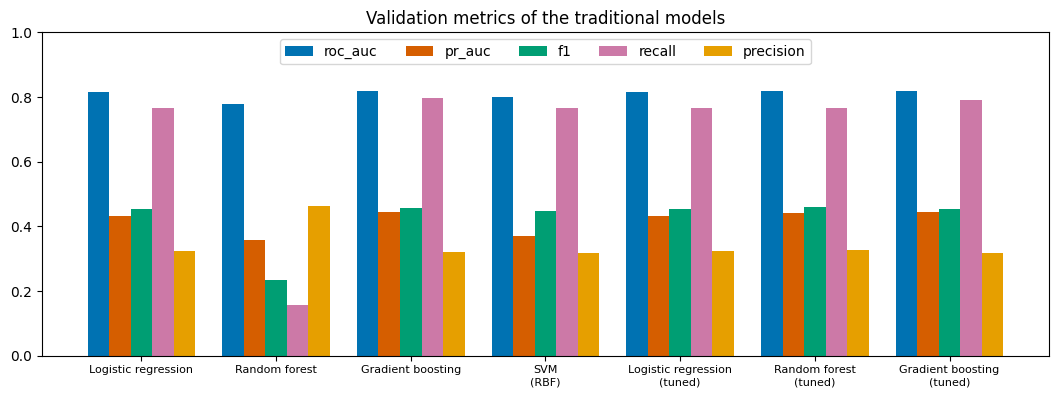

In [37]:
# Bar chart of the main metrics for the models trained on the full feature set
main_ids = ["T02", "T03", "T04", "T05", "T06", "T07", "T08"]
metrics_to_plot = ["roc_auc", "pr_auc", "f1", "recall", "precision"]
names = [results[i]["name"].replace(" (", "\n(") for i in main_ids]
colors = [BLUE, ORANGE, "#009E73", "#CC79A7", "#E69F00"]

fig, ax = plt.subplots(figsize=(13, 4.2))
width = 0.16
for k, metric in enumerate(metrics_to_plot):
    ax.bar(np.arange(len(main_ids)) + (k - 2) * width, [results[i]["metrics"][metric] for i in main_ids],
           width, label=metric, color=colors[k])
ax.set_xticks(range(len(main_ids))); ax.set_xticklabels(names, fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Validation metrics of the traditional models"); ax.legend(ncol=5, loc="upper center")
save_and_show("ml03_model_comparison")

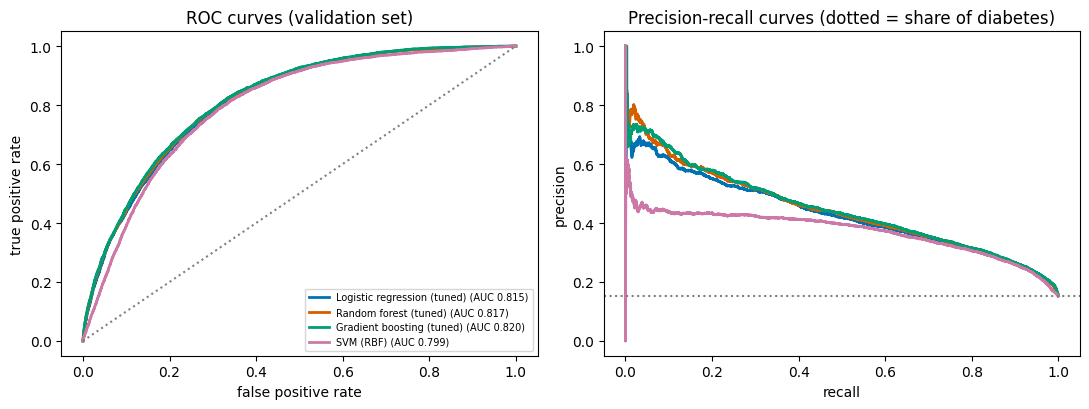

In [38]:
# ROC and precision-recall curves for the tuned models and the SVM
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for exp_id, color in [("T06", BLUE), ("T07", ORANGE), ("T08", "#009E73"), ("T05", "#CC79A7")]:
    fpr, tpr, _ = roc_curve(y_val, results[exp_id]["score"])
    prec, rec, _ = precision_recall_curve(y_val, results[exp_id]["score"])
    label = f"{results[exp_id]['name']} (AUC {results[exp_id]['metrics']['roc_auc']:.3f})"
    ax[0].plot(fpr, tpr, color=color, lw=2, label=label)
    ax[1].plot(rec, prec, color=color, lw=2)
ax[0].plot([0, 1], [0, 1], ":", color="grey"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC curves (validation set)"); ax[0].legend(fontsize=7, loc="lower right")
ax[1].axhline(y_val.mean(), color="grey", ls=":"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall curves (dotted = share of diabetes)")
plt.tight_layout()
save_and_show("ml04_roc_pr_curves")

## 25. Learning curve for the best model type
How much does the score improve when the model sees more training data? If both curves are flat and close together, more data will not help much; a large gap means the model overfits.

18:14:16 | curve logged to TensorBoard run 'curve_learning_size_gradient_boosting': train_roc_auc, cv_roc_auc


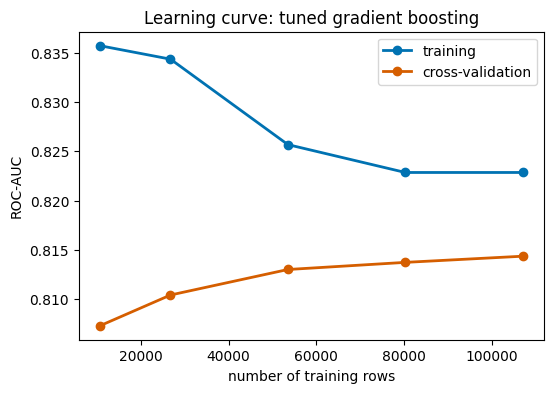

  rows  train AUC  CV AUC
 10708     0.8357  0.8073
 26771     0.8344  0.8104
 53543     0.8257  0.8130
 80315     0.8229  0.8137
107087     0.8229  0.8144


In [39]:
sizes, train_auc, cv_auc = learning_curve(clone(hgb_search.best_estimator_), train_scaled, y_train,
                                          train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=CV, scoring="roc_auc", n_jobs=-1)
tracker.log_curve("curve_learning_size_gradient_boosting",
                  {"train_roc_auc": train_auc.mean(axis=1), "cv_roc_auc": cv_auc.mean(axis=1)}, sizes)

plt.figure(figsize=(6, 4))
plt.plot(sizes, train_auc.mean(axis=1), color=BLUE, marker="o", lw=2, label="training")
plt.plot(sizes, cv_auc.mean(axis=1), color=ORANGE, marker="o", lw=2, label="cross-validation")
plt.xlabel("number of training rows"); plt.ylabel("ROC-AUC"); plt.title("Learning curve: tuned gradient boosting"); plt.legend()
save_and_show("ml05_learning_curve_size")
print(pd.DataFrame({"rows": sizes, "train AUC": train_auc.mean(axis=1).round(4), "CV AUC": cv_auc.mean(axis=1).round(4)}).to_string(index=False))

## 26. Choose and save the best traditional model
The best model is chosen by **validation ROC-AUC** among the SVM and the three tuned models (not by the test set). I fixed this rule before looking at the results, because several models differ only in the fourth decimal. I save the preprocessing step together with the model, so the saved file accepts the raw answer columns (with the four engineered columns added by `add_features`).

In [40]:
# The rule is fixed before looking at results: best validation ROC-AUC among the main models
# (SVM and the three tuned models). T09 to T11 reuse the tuned boosting model with one change each,
# so they are experiments about features and imbalance, not separate contenders.
candidates = ["T05", "T06", "T07", "T08"]
best_id = max(candidates, key=lambda i: results[i]["metrics"]["roc_auc"])
best = results[best_id]
print(f"Best traditional model: {best_id} - {best['name']}")
print({k: round(float(v), 4) for k, v in best["metrics"].items()})
print("Runner-ups by ROC-AUC:", {i: round(float(results[i]["metrics"]["roc_auc"]), 4) for i in candidates if i != best_id})

# ToDataFrame puts the column names back, because the models were trained on a table with named columns
columns = list(transform_to_frame(best["prep"], X_val.head(1)).columns)
best_pipeline = Pipeline([("prep", best["prep"]), ("to_frame", ToDataFrame(columns)), ("model", best["model"])])
joblib.dump(best_pipeline, MODELS / "best_traditional_model.joblib")

# Reload the file and check that it gives the same scores on the raw validation data
reloaded = joblib.load(MODELS / "best_traditional_model.joblib")
if hasattr(reloaded, "predict_proba"):
    new_scores = reloaded.predict_proba(X_val)[:, 1]
else:
    new_scores = reloaded.decision_function(X_val)
print("Largest difference after reloading:", float(np.abs(new_scores - best["score"]).max()))

Best traditional model: T08 - Gradient boosting (tuned)
{'accuracy': 0.7083, 'precision': 0.3179, 'recall': 0.792, 'f1': 0.4536, 'roc_auc': 0.8199, 'pr_auc': 0.4457}
Runner-ups by ROC-AUC: {'T05': 0.7995, 'T06': 0.8149, 'T07': 0.817}
Largest difference after reloading: 0.0


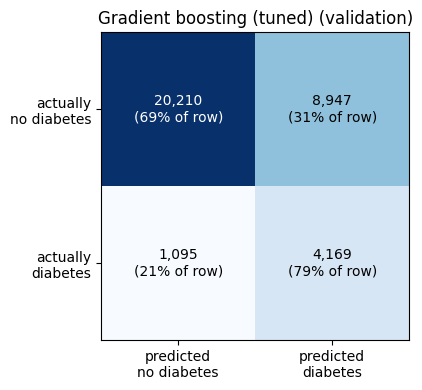

In [41]:
# Confusion matrix of the best model on the validation set
cm = confusion_matrix(y_val, best["pred"])
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
ax.set_title(f"{best['name']} (validation)")
save_and_show("ml06_confusion_matrix_best")

## 27. Observations for the experiment table
Short factual notes for each run. They are written into `reports/experiment_log.csv`. I will rewrite them in my own words and add the *why* in the report.

In [42]:
observations = {
    "T01": "Accuracy 0.847 only because it answers 'no diabetes' for everyone: recall 0, F1 0, ROC-AUC 0.50. Shows that accuracy is misleading on this data.",
    "T02": "Class-weighted linear model: ROC-AUC 0.815, recall 0.77 but precision only 0.32. Trains in 0.4 s. A strong, cheap reference point.",
    "T03": "Unlimited-depth forest: ROC-AUC 0.779 and recall only 0.16 at the 0.5 cut-off. AUC rose from 0.735 (10 trees) to 0.776 (100) and 0.779 (200), so more trees help little. Tuning (T07) fixed most of the gap with shallower trees.",
    "T04": "Default boosting is already the best untuned model: ROC-AUC 0.820, PR-AUC 0.445, in 2.6 s.",
    "T05": "SVM trained on 20,000 rows (about 12% of the training set): ROC-AUC 0.800. Not a fair comparison with the full-data models, and the cost of the SVM grows quickly with more rows.",
    "T06": "Tuning changed nothing: C from 0.01 to 10 and class weighting gave CV ROC-AUC between 0.8084 and 0.8086. The limit comes from the linear form of the model, not from the regularisation.",
    "T07": "Best settings: max_depth 12, min_samples_leaf 50, max_features 0.5. ROC-AUC rose from 0.779 (T03) to 0.817 and F1 0.460 is the highest F1 of all runs. Shallower, smoother trees reduced the overfitting of T03.",
    "T08": "Best traditional model: learning_rate 0.05, max_leaf_nodes 15, min_samples_leaf 20, l2 10. ROC-AUC 0.8199, PR-AUC 0.4457. Gain over the default T04 is only 0.0002 in AUC, so tuning barely mattered.",
    "T09": "Same model without the 4 engineered features: ROC-AUC 0.8195 vs 0.8199 and PR-AUC 0.4455 vs 0.4457. No measurable benefit from the new features on this split (run-to-run variation was not measured).",
    "T10": "Without class weights the ranking quality is the same (ROC-AUC 0.8200), but recall falls from 0.79 to 0.17 while precision rises from 0.32 to 0.58 and accuracy to 0.855. Class weights change the balance of errors at the 0.5 cut-off, not how well people are ranked.",
    "T11": "SMOTE (training set only): ROC-AUC 0.818, recall 0.25, precision 0.54. It moves the balance of errors less than class weights and the AUC is slightly lower than T08."
}
tracker.set_observations(observations)
tracker.read()[["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
0,D01,Neural net 64-32,0.8196,"Baseline. Validation ROC-AUC 0.8196, best epoc..."
1,D02,Neural net 128-64-32,0.8190,Wider and deeper: ROC-AUC 0.8190 (-0.0006 vs D...
2,D03,Neural net 32,0.8191,Single hidden layer of 32: ROC-AUC 0.8191 (-0....
3,D04,Neural net 64-32 + dropout 0.3,0.8199,"Dropout 0.3: ROC-AUC 0.8199 (+0.0003 vs D01, w..."
4,D05,Neural net 64-32 + batch norm,0.8181,Batch normalization: ROC-AUC 0.8181 (-0.0015 v...
5,D06,Neural net 64-32 + sgd + lr 0.01,0.8191,SGD with momentum (learning rate 0.01): ROC-AU...
6,D07,Neural net 64-32 + rmsprop,0.8195,"RMSprop: ROC-AUC 0.8195, PR-AUC 0.4454. Very c..."
7,D08,Neural net 64-32 + lr 0.01,0.8193,Adam with a 10 times larger learning rate (0.0...
8,D09,Neural net 64-32 + lr 0.0001,0.8189,Adam with a 10 times smaller learning rate (0....
9,D10,Neural net 64-32 + class weights,0.8195,Class weights: ROC-AUC 0.8195 (same ranking qu...


## 28. Viewing the logs in TensorBoard
In a terminal, from the project folder:
```
.venv/bin/tensorboard --logdir logs/tensorboard
```
Then open http://localhost:6006. The **HParams** tab lists every experiment with its settings and metrics (sortable); the **Scalars** tab shows the `curve_*` runs (boosting loss and AUC per round, forest AUC per tree count, logistic-regression grid, learning curve).

In [43]:
print("TensorBoard runs written:", len(list((LOGS / "tensorboard").iterdir())))
print("Experiment table:", (REPORTS / "experiment_log.csv").relative_to(ROOT), "| text log:", (LOGS / "step4_traditional_ml.log").relative_to(ROOT))

TensorBoard runs written: 28
Experiment table: reports/experiment_log.csv | text log: logs/step4_traditional_ml.log


## 29. Step 4 summary

**Facts from the output above:**
- **Best traditional model:** T08, tuned gradient boosting. On the validation set: ROC-AUC 0.820, PR-AUC 0.446, F1 0.454, recall 0.79, precision 0.32. It is saved in `models/best_traditional_model.joblib`, and reloading it gives identical scores.
- Every reasonable model ends up at ROC-AUC 0.80 to 0.82. Only the untuned forest (0.779) and the SVM trained on a small sample (0.800) are lower. Tuning made little difference for logistic regression and boosting, and a large difference for the forest (0.779 to 0.817).
- **Boosting curve:** validation AUC peaks around round 80 and then slowly declines, while the training loss keeps falling and the validation loss stays flat. That is mild overfitting after about 80 rounds.
- **Learning curve (training size):** with all the training data the training AUC is 0.823 and the cross-validated AUC 0.814. The gap is small, and going from 10% to 100% of the data raises the CV AUC by only about 0.007.
- The four engineered features gave no measurable gain (AUC 0.8199 with them, 0.8195 without).
- Class weights, no weights and SMOTE give almost the same ROC-AUC. They differ in how errors are split: with class weights the model finds 79% of diabetes cases but about two out of three of its "diabetes" predictions are false alarms; without weights it finds only 17% with higher precision.
- The test set has **not** been used yet.

**To write in my own words before the report:**
1. Why might all the models plateau near 0.82 ROC-AUC? (Think about what 21 survey answers can and cannot tell, and about the label noise found in Step 3.)
2. For a screening tool, which matters more, recall or precision? Which setting from T08, T10 or T11 would I choose, and why?
3. Why might the engineered features have added nothing, even though they showed a clear pattern in the plot?

---
# Step 5: Deep learning (TensorFlow / Keras)

**What is a neural network?** It is a stack of layers. Each layer multiplies its inputs by weights, adds a bias and applies an activation function. The first layer receives the 25 features of one person, and the last layer outputs one number between 0 and 1: the predicted probability of diabetes. During training the network repeatedly looks at small groups of people (a *batch*), measures its error with a *loss function*, and nudges the weights to reduce that error (this is what the *optimizer* does). One pass over all training rows is an *epoch*.

**The model I build (Keras Sequential API)**

| Part | Choice | Why |
|---|---|---|
| Input | 25 numbers (the scaled features from Step 3) | Same data as the scikit-learn models, so the comparison is fair |
| Hidden layers | `Dense` layers with ReLU activation | ReLU is the standard, simple choice for tabular data |
| Output | 1 neuron with sigmoid | Two classes, so one probability between 0 and 1 is enough |
| Loss | binary cross-entropy | The usual loss for a yes/no target |
| Metrics | AUC, precision, recall, accuracy | Accuracy alone is misleading on this imbalanced data |

**Data pipeline with `tf.data`.** The data goes into the network through a `tf.data` pipeline: it *shuffles* the training rows every epoch, groups them into *batches* of 256, and *prefetches* the next batch while the current one is being used.

**Training safeguards (callbacks)**
- `EarlyStopping`: stops when the validation AUC has not improved for 6 epochs, and goes back to the best epoch. This limits overfitting.
- `ModelCheckpoint`: saves the best version of the model during training.
- `ReduceLROnPlateau`: halves the learning rate when progress stalls.
- `TensorBoard` and `CSVLogger`: record the loss and metrics of every epoch in `logs/`.

**Experiment plan.** I change **one thing at a time** compared with a simple baseline (D01), so any difference can be linked to that change. The last experiment (D11) combines two of the changes, chosen for a clear purpose (see section 36).

| ID | What changes compared with the baseline D01 (layers 64-32, Adam, learning rate 0.001, no dropout) |
|---|---|
| D01 | Baseline |
| D02 | Wider and deeper: 128-64-32 |
| D03 | Smaller: one layer of 32 |
| D04 | Dropout 0.3 (randomly switches off neurons while training, to reduce overfitting) |
| D05 | Batch normalization (rescales each layer's outputs, can make training steadier) |
| D06 | Optimizer SGD with momentum (learning rate 0.01) |
| D07 | Optimizer RMSprop |
| D08 | Learning rate 0.01 (10 times bigger) |
| D09 | Learning rate 0.0001 (10 times smaller) |
| D10 | Class weights (the diabetes class counts more in the loss) |
| D11 | Combination: hidden_layers=(64, 32), dropout=0.3, batch_norm=False, optimizer=adam, learning_rate=0.001, use_class_weights=True |

As in Step 4, every model is trained on the training set and compared on the validation set. The test set stays untouched.

## 30. Setup

In [44]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BATCH_SIZE = 256          # how many people the network looks at before updating its weights
MAX_EPOCHS = 40           # upper limit, early stopping usually stops sooner

CHECKPOINT_DIR = MODELS / "checkpoints"
CSV_LOG_DIR = LOGS / "training_csv"
CHECKPOINT_DIR.mkdir(exist_ok=True)
CSV_LOG_DIR.mkdir(exist_ok=True)

# A new tracker for this step: same experiment table and TensorBoard folder, but its own text log file.
tracker = ExperimentTracker(REPORTS / "experiment_log.csv", LOGS / "tensorboard", LOGS / "step5_deep_learning.log")

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.18.0 | Keras 3.15.1


## 31. Helper functions
Three small functions keep the experiments short:
1. `make_dataset` builds the `tf.data` pipeline.
2. `build_model` creates the network from a list of layer sizes.
3. `run_dl_experiment` builds, trains and evaluates one network and records it (CSV table, text log, TensorBoard).

In [45]:
def make_dataset(features, labels, shuffle):
    # Turn the tables of features and labels into a tf.data pipeline.
    dataset = tf.data.Dataset.from_tensor_slices((features.values.astype("float32"), labels.values.astype("float32")))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(labels), seed=SEED)   # mix the rows (training only)
    dataset = dataset.batch(BATCH_SIZE)                                 # groups of 256 people
    dataset = dataset.prefetch(tf.data.AUTOTUNE)                        # prepare the next batch in advance
    return dataset


def build_model(n_features, hidden_layers, dropout=0.0, batch_norm=False):
    # Build a network: input -> hidden layers -> one sigmoid output.
    model = keras.Sequential()
    model.add(keras.Input(shape=(n_features,)))
    for units in hidden_layers:
        model.add(layers.Dense(units))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model


def make_optimizer(name, learning_rate):
    # Pick the optimizer by name.
    if name == "adam":
        return keras.optimizers.Adam(learning_rate)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate, momentum=0.9)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate)
    raise ValueError("unknown optimizer: " + name)


train_ds = make_dataset(train_scaled, y_train, shuffle=True)
val_ds = make_dataset(val_scaled, y_val, shuffle=False)      # no shuffling, so predictions stay in the same order as y_val
print("Batches per epoch:", len(train_ds), "| validation batches:", len(val_ds))

Batches per epoch: 628 | validation batches: 135


In [46]:
dl_results = {}      # exp_id -> the trained model, its scores, its training history and metrics

def run_dl_experiment(exp_id, hidden_layers, dropout=0.0, batch_norm=False, optimizer="adam",
                      learning_rate=0.001, use_class_weights=False):
    # Build, train and evaluate one network, then record it.
    keras.utils.set_random_seed(SEED)                 # same starting weights in every experiment
    layer_text = "-".join(str(u) for u in hidden_layers)
    model_name = f"Neural net {layer_text}"
    if dropout > 0:
        model_name += f" + dropout {dropout}"
    if batch_norm:
        model_name += " + batch norm"
    if optimizer != "adam":
        model_name += f" + {optimizer}"
    if learning_rate != 0.001:
        model_name += f" + lr {learning_rate}"
    if use_class_weights:
        model_name += " + class weights"
    run_name = tracker.run_name(exp_id, model_name)
    tb_folder = tracker.reset_run(run_name)           # empty TensorBoard folder; Keras writes the epoch curves here

    model = build_model(train_scaled.shape[1], hidden_layers, dropout, batch_norm)
    model.compile(optimizer=make_optimizer(optimizer, learning_rate),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"), "accuracy"])

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(CHECKPOINT_DIR / f"{exp_id}.keras", monitor="val_auc", mode="max", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3),
        keras.callbacks.TensorBoard(log_dir=str(tb_folder)),
        keras.callbacks.CSVLogger(str(CSV_LOG_DIR / f"{exp_id}.csv")),
    ]

    start = time.time()
    # shuffle=False because the tf.data pipeline already shuffles the training rows every epoch
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, verbose=0, shuffle=False,
                        class_weight=class_weight if use_class_weights else None, callbacks=callbacks)
    seconds = time.time() - start

    # After early stopping the model holds the weights of the best epoch.
    scores = model.predict(val_ds, verbose=0).ravel()
    metrics = evaluate_binary(y_val.values, scores)
    best_epoch = int(np.argmax(history.history["val_auc"])) + 1

    params = {"hidden_layers": layer_text, "dropout": dropout, "batch_norm": batch_norm, "optimizer": optimizer,
              "learning_rate": learning_rate, "class_weights": use_class_weights, "batch_size": BATCH_SIZE,
              "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch}
    tracker.log_experiment(exp_id, "5 deep learning", model_name, params, FEATURES_ALL, SPLIT_TEXT,
                           f"validation ({len(y_val):,} rows)", metrics, seconds, keep_existing_run=True)
    dl_results[exp_id] = {"name": model_name, "model": model, "score": scores, "history": history.history,
                          "metrics": metrics, "params": params}
    return metrics


def show_dl_results(ids):
    # Small table with the results of some deep learning experiments.
    rows = []
    for i in ids:
        p = dl_results[i]["params"]
        rows.append({"exp": i, "layers": p["hidden_layers"], "epochs": p["epochs_run"], "best epoch": p["best_epoch"],
                     **{k: round(v, 3) for k, v in dl_results[i]["metrics"].items()}})
    return pd.DataFrame(rows).set_index("exp")

## 32. Experiments D01 to D03: the baseline and the size of the network

In [47]:
# D01: baseline, two hidden layers (64 and 32 neurons), Adam, learning rate 0.001
run_dl_experiment("D01", hidden_layers=(64, 32))

# D02: wider and deeper network
run_dl_experiment("D02", hidden_layers=(128, 64, 32))

# D03: smaller network, a single hidden layer
run_dl_experiment("D03", hidden_layers=(32,))

show_dl_results(["D01", "D02", "D03"])

18:14:32 | D01 | Neural net 64-32 | acc 0.856 | precision 0.606 | recall 0.160 | F1 0.253 | ROC-AUC 0.820 | PR-AUC 0.443 | 15.1s


18:14:53 | D02 | Neural net 128-64-32 | acc 0.854 | precision 0.575 | recall 0.173 | F1 0.266 | ROC-AUC 0.819 | PR-AUC 0.439 | 21.1s


18:15:20 | D03 | Neural net 32 | acc 0.855 | precision 0.597 | recall 0.156 | F1 0.248 | ROC-AUC 0.819 | PR-AUC 0.441 | 26.4s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D02,128-64-32,16,10,0.854,0.575,0.173,0.266,0.819,0.439
D03,32,28,22,0.855,0.597,0.156,0.248,0.819,0.441


## 33. Experiments D04 and D05: regularization (against overfitting)
Both start from the baseline D01 and add one technique.

In [48]:
# D04: dropout 0.3 after every hidden layer
run_dl_experiment("D04", hidden_layers=(64, 32), dropout=0.3)

# D05: batch normalization after every hidden layer
run_dl_experiment("D05", hidden_layers=(64, 32), batch_norm=True)

show_dl_results(["D01", "D04", "D05"])

18:15:58 | D04 | Neural net 64-32 + dropout 0.3 | acc 0.854 | precision 0.625 | recall 0.121 | F1 0.202 | ROC-AUC 0.820 | PR-AUC 0.444 | 37.4s


18:16:13 | D05 | Neural net 64-32 + batch norm | acc 0.854 | precision 0.572 | recall 0.186 | F1 0.280 | ROC-AUC 0.818 | PR-AUC 0.440 | 15.5s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D04,64-32,31,25,0.854,0.625,0.121,0.202,0.820,0.444
D05,64-32,12,6,0.854,0.572,0.186,0.280,0.818,0.440


## 34. Experiments D06 to D09: optimizer and learning rate
The optimizer decides *how* the weights are updated, and the learning rate decides *how big* each update is.

In [49]:
# D06: SGD with momentum (needs a bigger learning rate than Adam)
run_dl_experiment("D06", hidden_layers=(64, 32), optimizer="sgd", learning_rate=0.01)

# D07: RMSprop
run_dl_experiment("D07", hidden_layers=(64, 32), optimizer="rmsprop", learning_rate=0.001)

# D08: Adam with a learning rate 10 times bigger
run_dl_experiment("D08", hidden_layers=(64, 32), learning_rate=0.01)

# D09: Adam with a learning rate 10 times smaller
run_dl_experiment("D09", hidden_layers=(64, 32), learning_rate=0.0001)

show_dl_results(["D01", "D06", "D07", "D08", "D09"])

18:16:40 | D06 | Neural net 64-32 + sgd + lr 0.01 | acc 0.854 | precision 0.572 | recall 0.185 | F1 0.279 | ROC-AUC 0.819 | PR-AUC 0.441 | 26.4s


18:16:54 | D07 | Neural net 64-32 + rmsprop | acc 0.855 | precision 0.585 | recall 0.185 | F1 0.281 | ROC-AUC 0.820 | PR-AUC 0.445 | 13.4s


18:17:11 | D08 | Neural net 64-32 + lr 0.01 | acc 0.855 | precision 0.591 | recall 0.174 | F1 0.269 | ROC-AUC 0.819 | PR-AUC 0.440 | 16.6s


18:17:52 | D09 | Neural net 64-32 + lr 0.0001 | acc 0.854 | precision 0.586 | recall 0.162 | F1 0.254 | ROC-AUC 0.819 | PR-AUC 0.441 | 41.5s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.820,0.443
D06,64-32,26,20,0.854,0.572,0.185,0.279,0.819,0.441
D07,64-32,13,7,0.855,0.585,0.185,0.281,0.820,0.445
D08,64-32,16,10,0.855,0.591,0.174,0.269,0.819,0.440
D09,64-32,40,40,0.854,0.586,0.162,0.254,0.819,0.441


## 35. Experiment D10: class weights
Same idea as in Step 4: each diabetes example counts more in the loss (weights 0.59 and 3.27 from Step 3).

In [50]:
run_dl_experiment("D10", hidden_layers=(64, 32), use_class_weights=True)
show_dl_results(["D01", "D10"])

18:18:10 | D10 | Neural net 64-32 + class weights | acc 0.707 | precision 0.317 | recall 0.794 | F1 0.453 | ROC-AUC 0.820 | PR-AUC 0.441 | 17.2s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.82,0.443
D10,64-32,16,10,0.707,0.317,0.794,0.453,0.82,0.441


## 36. Experiment D11: combining what helped
After D01 to D10 (validation results only) none of the single changes moved the ROC-AUC by more than about 0.001, so choosing by AUC would only follow noise. I combine two changes that each have a clear purpose: **dropout** (the best AUC by a tiny margin, and the standard protection against overfitting) and **class weights** (the only change that clearly changed recall and precision). The settings are: **hidden_layers=(64, 32), dropout=0.3, batch_norm=False, optimizer=adam, learning_rate=0.001, use_class_weights=True**.

In [51]:
run_dl_experiment("D11", hidden_layers=(64, 32), dropout=0.3, batch_norm=False, optimizer='adam',
                  learning_rate=0.001, use_class_weights=True)
show_dl_results(["D01", "D11"])

18:18:56 | D11 | Neural net 64-32 + dropout 0.3 + class weights | acc 0.698 | precision 0.312 | recall 0.809 | F1 0.451 | ROC-AUC 0.820 | PR-AUC 0.443 | 46.2s


,layers,epochs,best epoch,accuracy,precision,recall,f1,roc_auc,pr_auc
exp,,,,,,,,,
D01,64-32,13,7,0.856,0.606,0.160,0.253,0.82,0.443
D11,64-32,29,23,0.698,0.312,0.809,0.451,0.82,0.443


## 37. Learning curves
A learning curve shows the loss and AUC after each epoch for the training data and the validation data.
- Both curves improving together: the network is still learning.
- Training keeps improving but validation stalls or gets worse: the network is **overfitting** (memorising the training rows).
- Both curves poor: **underfitting** (the network is too simple, or trained too little).

One caution: Keras measures the *training* curve while the weights are still changing during the epoch (and with dropout switched on), so it can look slightly worse than the validation curve. That is normal and not a sign of a bug.

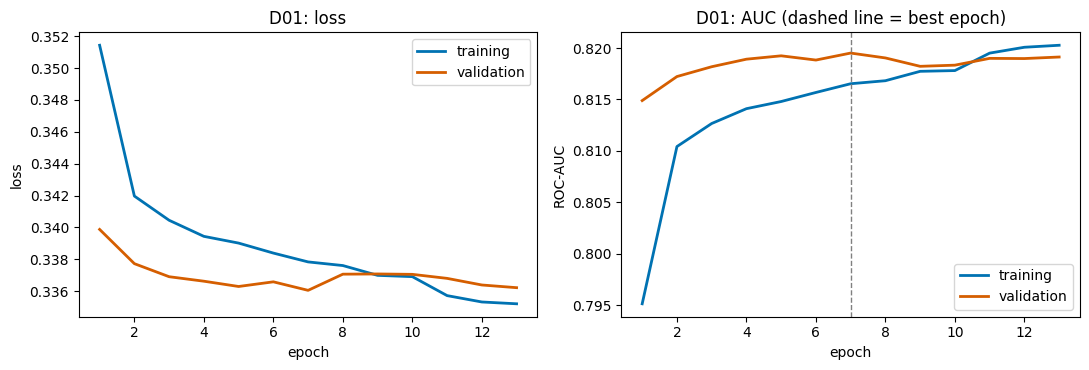

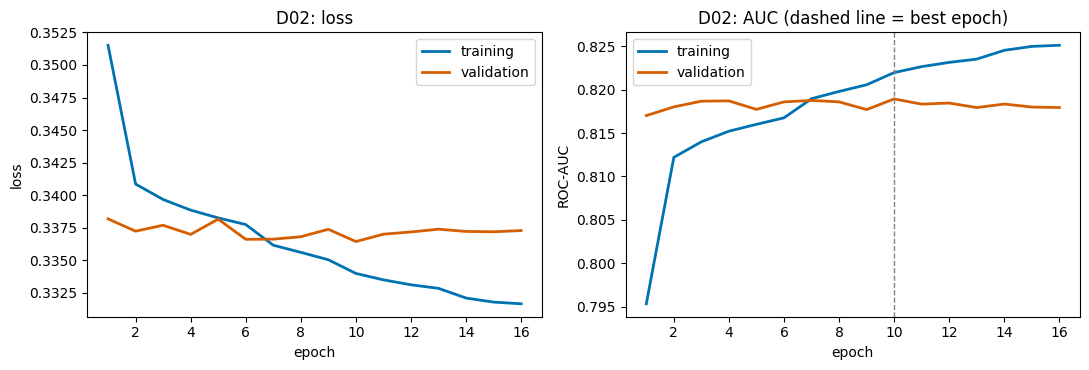

In [52]:
def plot_learning_curves(exp_id):
    # Loss and AUC per epoch, training vs validation.
    h = dl_results[exp_id]["history"]
    epochs = range(1, len(h["loss"]) + 1)
    best_epoch = dl_results[exp_id]["params"]["best_epoch"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(epochs, h["loss"], color=BLUE, lw=2, label="training")
    ax[0].plot(epochs, h["val_loss"], color=ORANGE, lw=2, label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title(f"{exp_id}: loss"); ax[0].legend()
    ax[1].plot(epochs, h["auc"], color=BLUE, lw=2, label="training")
    ax[1].plot(epochs, h["val_auc"], color=ORANGE, lw=2, label="validation")
    ax[1].axvline(best_epoch, color="grey", ls="--", lw=1)
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("ROC-AUC"); ax[1].set_title(f"{exp_id}: AUC (dashed line = best epoch)"); ax[1].legend()
    plt.tight_layout()
    save_and_show(f"dl_learning_curves_{exp_id}")

plot_learning_curves("D01")      # the baseline
plot_learning_curves("D02")      # the biggest network

In [53]:
# Numbers behind the curves: how large is the gap between training and validation at the best epoch?
rows = []
for exp_id, r in dl_results.items():
    h, best = r["history"], r["params"]["best_epoch"] - 1
    rows.append({"exp": exp_id, "best epoch": best + 1, "train AUC": round(h["auc"][best], 4), "val AUC": round(h["val_auc"][best], 4),
                 "gap": round(h["auc"][best] - h["val_auc"][best], 4),
                 "train loss": round(h["loss"][best], 4), "val loss": round(h["val_loss"][best], 4)})
pd.DataFrame(rows).set_index("exp")

,best epoch,train AUC,val AUC,gap,train loss,val loss
exp,,,,,,
D01,7,0.8165,0.8195,-0.0030,0.3378,0.3361
D02,10,0.8220,0.8189,0.0030,0.3340,0.3364
D03,22,0.8177,0.8191,-0.0014,0.3370,0.3364
D04,25,0.8133,0.8198,-0.0065,0.3407,0.3361
D05,6,0.8163,0.8181,-0.0018,0.3380,0.3372
D06,20,0.8177,0.8191,-0.0013,0.3370,0.3364
D07,7,0.8161,0.8195,-0.0033,0.3380,0.3360
D08,10,0.8176,0.8193,-0.0017,0.3372,0.3370
D09,40,0.8174,0.8189,-0.0014,0.3371,0.3364


## 38. Choose the best neural network
Rule, fixed before looking: the network with the highest **validation ROC-AUC** among D01 to D11 (the test set is not used). If several networks are within 0.001 AUC of each other, they are practically tied, and I say so in the report.

Best neural network: D04 - Neural net 64-32 + dropout 0.3
{'accuracy': 0.8544, 'precision': 0.625, 'recall': 0.1206, 'f1': 0.2022, 'roc_auc': 0.8199, 'pr_auc': 0.444}
Networks within 0.001 AUC of the best: {'D01': 0.8196, 'D02': 0.819, 'D03': 0.8191, 'D06': 0.8191, 'D07': 0.8195, 'D08': 0.8193, 'D10': 0.8195, 'D11': 0.8195}


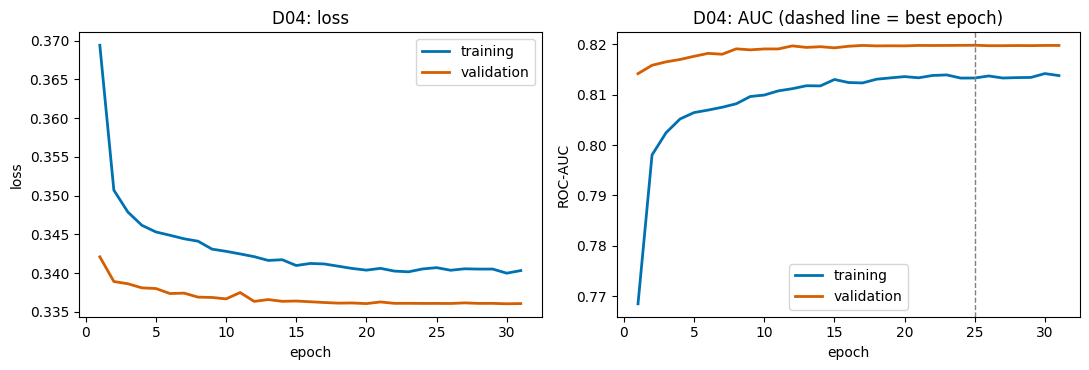

In [54]:
best_dl_id = max(dl_results, key=lambda i: dl_results[i]["metrics"]["roc_auc"])
best_dl = dl_results[best_dl_id]
print(f"Best neural network: {best_dl_id} - {best_dl['name']}")
print({k: round(float(v), 4) for k, v in best_dl["metrics"].items()})
close = {i: round(float(r["metrics"]["roc_auc"]), 4) for i, r in dl_results.items() if i != best_dl_id and r["metrics"]["roc_auc"] > best_dl["metrics"]["roc_auc"] - 0.001}
print("Networks within 0.001 AUC of the best:", close if close else "none")
plot_learning_curves(best_dl_id)

In [55]:
# All deep learning experiments, sorted by validation ROC-AUC
table = tracker.read()
dl_table = table[table["step"] == "5 deep learning"][["exp_id", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds"]]
dl_table.sort_values("roc_auc", ascending=False).reset_index(drop=True)

,exp_id,model,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
0,D04,Neural net 64-32 + dropout 0.3,0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,37.4
1,D01,Neural net 64-32,0.8556,0.6060,0.1601,0.2533,0.8196,0.4430,15.1
2,D07,Neural net 64-32 + rmsprop,0.8553,0.5853,0.1850,0.2812,0.8195,0.4454,13.4
3,D10,Neural net 64-32 + class weights,0.7069,0.3169,0.7935,0.4530,0.8195,0.4406,17.2
4,D11,Neural net 64-32 + dropout 0.3 + class weights,0.6981,0.3122,0.8093,0.4506,0.8195,0.4432,46.2
5,D08,Neural net 64-32 + lr 0.01,0.8552,0.5907,0.1738,0.2686,0.8193,0.4399,16.6
6,D03,Neural net 32,0.8549,0.5972,0.1563,0.2478,0.8191,0.4412,26.4
7,D06,Neural net 64-32 + sgd + lr 0.01,0.8542,0.5720,0.1848,0.2794,0.8191,0.4406,26.4
8,D02,Neural net 128-64-32,0.8539,0.5746,0.1727,0.2656,0.8190,0.4393,21.1
9,D09,Neural net 64-32 + lr 0.0001,0.8544,0.5863,0.1620,0.2539,0.8189,0.4409,41.5


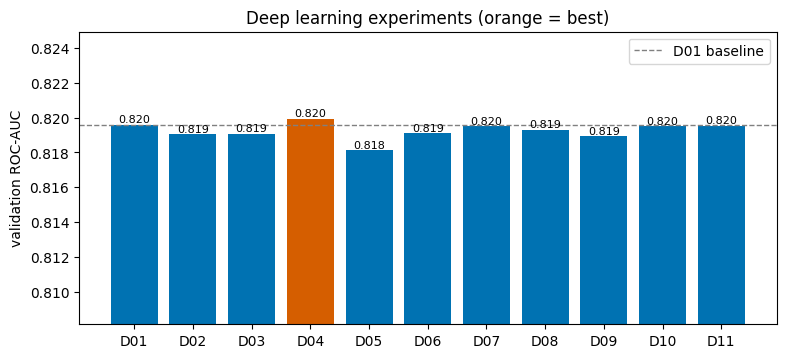

In [56]:
# Bar chart: validation ROC-AUC of every deep learning experiment (D01 is the reference)
ids = list(dl_results)
aucs = [dl_results[i]["metrics"]["roc_auc"] for i in ids]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(ids, aucs, color=[ORANGE if i == best_dl_id else BLUE for i in ids])
ax.axhline(dl_results["D01"]["metrics"]["roc_auc"], color="grey", ls="--", lw=1, label="D01 baseline")
ax.set_ylim(min(aucs) - 0.01, max(aucs) + 0.005)
ax.set_ylabel("validation ROC-AUC"); ax.set_title("Deep learning experiments (orange = best)"); ax.legend()
for i, a in zip(ids, aucs):
    ax.text(i, a, f"{a:.3f}", ha="center", va="bottom", fontsize=8)
save_and_show("dl_experiment_comparison")

## 39. Save and reload the best neural network
Two files are saved: the whole model (`.keras`, architecture and weights) and the weights alone (`.weights.h5`). Both go in the Google Drive folder. Then I reload the model and check that it gives the same predictions.

In [57]:
best_dl["model"].save(MODELS / "best_deep_learning_model.keras")
best_dl["model"].save_weights(MODELS / "best_deep_learning_model.weights.h5")

reloaded_model = keras.models.load_model(MODELS / "best_deep_learning_model.keras")
new_scores = reloaded_model.predict(val_ds, verbose=0).ravel()
print("Largest difference in predictions after reloading:", float(np.abs(new_scores - best_dl["score"]).max()))
print("Saved files:", sorted(f.name for f in MODELS.glob("best_*")))

Largest difference in predictions after reloading: 0.0
Saved files: ['best_deep_learning_model.keras', 'best_deep_learning_model.weights.h5', 'best_traditional_model.joblib']


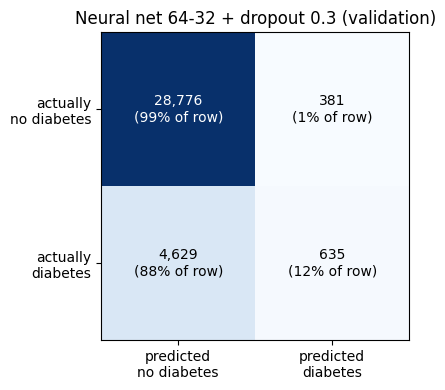

In [58]:
# Confusion matrix of the best neural network on the validation set (cut-off 0.5)
pred = (best_dl["score"] >= 0.5).astype(int)
cm = confusion_matrix(y_val, pred)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
ax.set_title(f"{best_dl['name']} (validation)")
save_and_show("dl_confusion_matrix_best")

## 40. Traditional machine learning vs deep learning (validation set)
The best model of each kind, plus the simple linear model as a reference. This is a first comparison; the final comparison on the test set comes in the error-analysis step.

In [59]:
compare = pd.DataFrame({
    "Logistic regression (T06)": results["T06"]["metrics"],
    f"Best traditional: {results[best_id]['name']} ({best_id})": results[best_id]["metrics"],
    f"Best deep learning: {best_dl['name']} ({best_dl_id})": best_dl["metrics"],
}).T.round(4)
compare["train_seconds"] = [tracker.read().set_index("exp_id").loc[i, "train_seconds"] for i in ["T06", best_id, best_dl_id]]
compare

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_seconds
Logistic regression (T06),0.7189,0.3231,0.7656,0.4544,0.8149,0.4305,0.4
Best traditional: Gradient boosting (tuned) (T08),0.7083,0.3179,0.7920,0.4536,0.8199,0.4457,3.4
Best deep learning: Neural net 64-32 + dropout 0.3 (D04),0.8544,0.6250,0.1206,0.2022,0.8199,0.4440,37.4


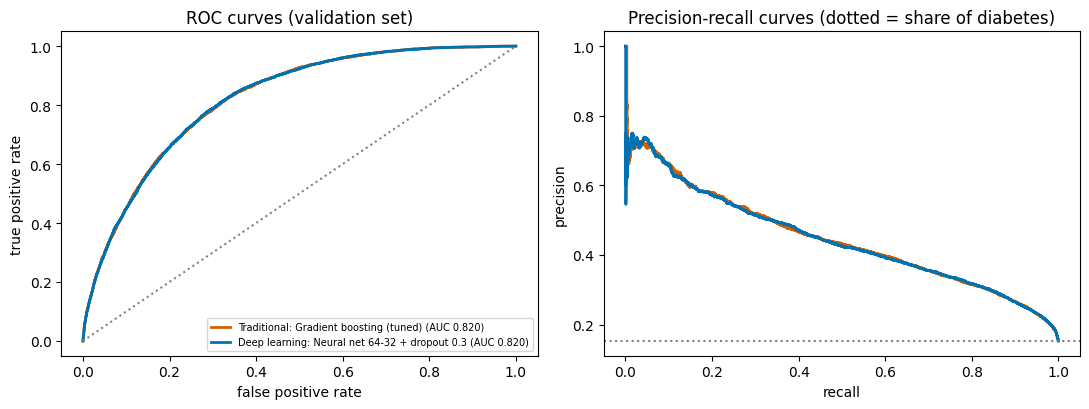

In [60]:
# ROC and precision-recall curves: best traditional model vs best neural network
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for label, scores, color in [(f"Traditional: {results[best_id]['name']}", results[best_id]["score"], ORANGE),
                             (f"Deep learning: {best_dl['name']}", best_dl["score"], BLUE)]:
    fpr, tpr, _ = roc_curve(y_val, scores)
    prec, rec, _ = precision_recall_curve(y_val, scores)
    ax[0].plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {roc_auc_score(y_val, scores):.3f})")
    ax[1].plot(rec, prec, color=color, lw=2)
ax[0].plot([0, 1], [0, 1], ":", color="grey"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC curves (validation set)"); ax[0].legend(fontsize=7, loc="lower right")
ax[1].axhline(y_val.mean(), color="grey", ls=":"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall curves (dotted = share of diabetes)")
plt.tight_layout()
save_and_show("dl_vs_ml_curves")

## 41. Observations for the experiment table
Short factual notes for each run, written into `reports/experiment_log.csv`. The numbers are filled in by the code from the results above. I will rewrite the notes in my own words and add the reasons in the report.

In [61]:
def m(exp_id, metric):
    return dl_results[exp_id]["metrics"][metric]

def par(exp_id, key):
    return dl_results[exp_id]["params"][key]

def gap(exp_id):
    # training AUC minus validation AUC at the best epoch
    h, best = dl_results[exp_id]["history"], par(exp_id, "best_epoch") - 1
    return h["auc"][best] - h["val_auc"][best]

dl_observations = {
    "D01": f"Baseline. Validation ROC-AUC {m('D01', 'roc_auc'):.4f}, best epoch {par('D01', 'best_epoch')} of {par('D01', 'epochs_run')}. Without class weights the recall at the 0.5 cut-off is only {m('D01', 'recall'):.2f} (precision {m('D01', 'precision'):.2f}).",
    "D02": f"Wider and deeper: ROC-AUC {m('D02', 'roc_auc'):.4f} ({m('D02', 'roc_auc') - m('D01', 'roc_auc'):+.4f} vs D01) with {par('D02', 'epochs_run')} epochs. Training AUC is {gap('D02'):+.3f} above validation at the best epoch, the largest gap of the runs, a hint of overfitting but no gain.",
    "D03": f"Single hidden layer of 32: ROC-AUC {m('D03', 'roc_auc'):.4f} ({m('D03', 'roc_auc') - m('D01', 'roc_auc'):+.4f} vs D01). A much smaller network scores about the same, so network size is not what limits the result; it needed {par('D03', 'best_epoch')} epochs to reach its best.",
    "D04": f"Dropout 0.3: ROC-AUC {m('D04', 'roc_auc'):.4f} ({m('D04', 'roc_auc') - m('D01', 'roc_auc'):+.4f} vs D01, within noise). Training is slower (best epoch {par('D04', 'best_epoch')}) and recall at the 0.5 cut-off drops to {m('D04', 'recall'):.2f}.",
    "D05": f"Batch normalization: ROC-AUC {m('D05', 'roc_auc'):.4f} ({m('D05', 'roc_auc') - m('D01', 'roc_auc'):+.4f} vs D01); training stopped after {par('D05', 'epochs_run')} epochs. No benefit on this small network.",
    "D06": f"SGD with momentum (learning rate 0.01): ROC-AUC {m('D06', 'roc_auc'):.4f}. It needed {par('D06', 'best_epoch')} epochs to reach its best against {par('D01', 'best_epoch')} for Adam, so it converges more slowly for the same quality.",
    "D07": f"RMSprop: ROC-AUC {m('D07', 'roc_auc'):.4f}, PR-AUC {m('D07', 'pr_auc'):.4f}. Very close to Adam (D01).",
    "D08": f"Adam with a 10 times larger learning rate (0.01): ROC-AUC {m('D08', 'roc_auc'):.4f}. Training did not become unstable here (ReduceLROnPlateau can halve the rate when progress stalls, which may hide an unstable start).",
    "D09": f"Adam with a 10 times smaller learning rate (0.0001): ROC-AUC {m('D09', 'roc_auc'):.4f}. Best epoch {par('D09', 'best_epoch')} of {par('D09', 'epochs_run')} (the limit is {MAX_EPOCHS}), so it was still improving when it was stopped and is probably not fully trained.",
    "D10": f"Class weights: ROC-AUC {m('D10', 'roc_auc'):.4f} (same ranking quality as D01) but recall {m('D10', 'recall'):.2f} against {m('D01', 'recall'):.2f}, precision {m('D10', 'precision'):.2f} against {m('D01', 'precision'):.2f}, accuracy {m('D10', 'accuracy'):.3f}. Class weights change the balance of errors, not how well people are ranked.",
    "D11": f"Dropout 0.3 + class weights: ROC-AUC {m('D11', 'roc_auc'):.4f}, recall {m('D11', 'recall'):.2f}, precision {m('D11', 'precision'):.2f}. Compare with D04 (dropout only) and D10 (class weights only).",
}
tracker.set_observations(dl_observations)
tracker.read()[tracker.read()["step"] == "5 deep learning"][["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
0,D01,Neural net 64-32,0.8196,"Baseline. Validation ROC-AUC 0.8196, best epoc..."
1,D02,Neural net 128-64-32,0.8190,Wider and deeper: ROC-AUC 0.8190 (-0.0006 vs D...
2,D03,Neural net 32,0.8191,Single hidden layer of 32: ROC-AUC 0.8191 (-0....
3,D04,Neural net 64-32 + dropout 0.3,0.8199,"Dropout 0.3: ROC-AUC 0.8199 (+0.0003 vs D01, w..."
4,D05,Neural net 64-32 + batch norm,0.8181,Batch normalization: ROC-AUC 0.8181 (-0.0015 v...
5,D06,Neural net 64-32 + sgd + lr 0.01,0.8191,SGD with momentum (learning rate 0.01): ROC-AU...
6,D07,Neural net 64-32 + rmsprop,0.8195,"RMSprop: ROC-AUC 0.8195, PR-AUC 0.4454. Very c..."
7,D08,Neural net 64-32 + lr 0.01,0.8193,Adam with a 10 times larger learning rate (0.0...
8,D09,Neural net 64-32 + lr 0.0001,0.8189,Adam with a 10 times smaller learning rate (0....
9,D10,Neural net 64-32 + class weights,0.8195,Class weights: ROC-AUC 0.8195 (same ranking qu...


## 42. Viewing the training in TensorBoard
```
.venv/bin/tensorboard --logdir logs/tensorboard
```
Open http://localhost:6006. For each `D..` run the **Scalars** tab shows the loss, AUC, precision, recall and accuracy after every epoch (training and validation in two lines). The **HParams** tab compares all experiments (T01 to T11 and D01 to D11) with their settings. The same numbers are in `logs/training_csv/` as CSV files, and the overview of every run is in `logs/step4_traditional_ml.log`, `logs/step5_deep_learning.log` and `reports/experiment_log.csv`.

In [62]:
print("TensorBoard runs written:", len(list((LOGS / "tensorboard").iterdir())))
print("Epoch-by-epoch CSV logs:", len(list(CSV_LOG_DIR.glob("*.csv"))))

TensorBoard runs written: 28
Epoch-by-epoch CSV logs: 11


## 43. Step 5 summary

**Facts from the output above:**
- I trained 11 neural networks (D01 to D11). With the 11 scikit-learn experiments of Step 4 there are now 22 logged experiments in `reports/experiment_log.csv`, each with a TensorBoard run.
- All 11 networks have a validation ROC-AUC between 0.818 and 0.820, so they are practically tied. The best one by my rule is **D04** (dropout 0.3, AUC 0.8199), but eight other networks are within 0.001 of it, so choosing between them means little. It is saved as `models/best_deep_learning_model.keras` (and `.weights.h5`), and reloading gives identical predictions.
- The best network (0.8199) reaches the same ROC-AUC as the tuned gradient boosting model from Step 4 (0.8199). This suggests, but does not prove, that the limit is the information in the 25 features and in the labels, and not the type of model.
- Network size did not matter: one layer of 32 neurons (0.8191) scored the same as 128-64-32 (0.8190).
- Overfitting is small. At the best epoch the gap between training and validation AUC stays between -0.007 and +0.003, and only the largest network (D02) has a training AUC above its validation AUC. Early stopping picked best epochs between 6 and 40.
- Optimizers and learning rates: SGD needed about 20 epochs against 7 for Adam, and the learning rate 0.0001 was still improving at the 40-epoch limit, so that run is probably not fully trained. Batch normalization gave the lowest AUC (0.8181).
- Class weights again changed the error balance and not the ranking: recall rose from 0.16 to 0.79 and precision fell from 0.61 to 0.32.
- Training a network took 17 to 76 seconds, against 3.6 seconds for the tuned gradient boosting model.
- The test set has **not** been used yet.

**To write in my own words before the report:**
1. Why did the network size, the optimizer and the learning rate change the ROC-AUC so little? How does this connect to the plateau I saw in Step 4?
2. Look at the learning curves of D01 and D02. Do I see overfitting or underfitting? Which numbers (gap, best epoch) support my answer?
3. For a screening tool, would I recommend the gradient boosting model (T08) or a neural network (D10 or D11)? Think about recall, precision, training time and how easy each is to explain.

---
# Step 6: Experiment tracking and comparison

So far I have 22 experiments. This step makes the experiment table something another person could trust and reproduce.

| Question | What I do in this step |
|---|---|
| Which experiment builds on which, and what exactly changed? | Add two columns, **builds on** and **single change**, so the order of the experiments tells a story |
| Are the small differences real or just noise? | Repeat the best traditional model on 5 different random splits and the baseline network with 5 different random starts, and measure the spread |
| Can every number in the table be traced to a logged run? | An **audit** compares each value in the table with the value stored in its TensorBoard run |
| What are the trade-offs between models? | Plots of the whole progression, of precision against recall, and of accuracy against training time |

The result is saved as `reports/experiment_table.csv` and `reports/experiment_table.md` (a table that can be pasted into the report).

## 44. Setup

In [63]:
import ast
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# A new tracker for this step (same experiment table and TensorBoard folder, own text log)
tracker = ExperimentTracker(REPORTS / "experiment_log.csv", LOGS / "tensorboard", LOGS / "step6_comparison.log")
print("Experiments in the log before this step:", len(tracker.read()))

Experiments in the log before this step: 24


## 45. How big is the random noise?
Up to now I compared models on **one** train/validation split, and the neural networks started from one random initialisation. Many differences were about 0.001 in ROC-AUC. To know whether such a difference means anything, I measure how much the score moves when only the randomness changes:

- **T12:** the tuned gradient boosting model (T08) on 5 different random 70/15/15 splits (seeds 1 to 5). For each split the preprocessing is fitted again on that split's training data only.
- **D12:** the baseline network (D01) trained 5 times with different random starting weights (seeds 1 to 5), on the same split. The shuffling seed of the `tf.data` pipeline is not changed.

Each experiment is logged as one row with the **mean** of the 5 repeats. The spread (standard deviation) is stored in the hyperparameters column.

In [64]:
# --- T12: same model, 5 different splits ---
start = time.time()
split_scores = []
for split_seed in [1, 2, 3, 4, 5]:
    X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(df_feat, seed=split_seed)
    prep = build_preprocessor(use_engineered=True).fit(X_tr)          # fitted on this split's training data only
    model = clone(hgb_search.best_estimator_)
    model.fit(transform_to_frame(prep, X_tr), y_tr)
    scores = model.predict_proba(transform_to_frame(prep, X_va))[:, 1]
    split_scores.append(evaluate_binary(y_va.values, scores))
gb_repeats = pd.DataFrame(split_scores, index=[f"split {s}" for s in [1, 2, 3, 4, 5]])
gb_seconds = time.time() - start
gb_repeats.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
split 1,0.7099,0.3187,0.7880,0.4538,0.8177,0.4356
split 2,0.7094,0.3167,0.7774,0.4500,0.8158,0.4405
split 3,0.7117,0.3206,0.7908,0.4563,0.8199,0.4438
split 4,0.7127,0.3210,0.7874,0.4560,0.8164,0.4294
split 5,0.7107,0.3192,0.7872,0.4543,0.8190,0.4393


In [65]:
# --- D12: same network, 5 different random starts ---
def train_network_once(seed):
    keras.utils.set_random_seed(seed)                       # changes the starting weights
    net = build_model(train_scaled.shape[1], (64, 32))
    net.compile(optimizer=make_optimizer("adam", 0.001), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    stop_early = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)
    net.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, verbose=0, shuffle=False, callbacks=[stop_early])
    return evaluate_binary(y_val.values, net.predict(val_ds, verbose=0).ravel())

start = time.time()
nn_repeats = pd.DataFrame([train_network_once(s) for s in [1, 2, 3, 4, 5]], index=[f"seed {s}" for s in [1, 2, 3, 4, 5]])
nn_seconds = time.time() - start
nn_repeats.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
seed 1,0.8550,0.5739,0.2014,0.2981,0.8186,0.4410
seed 2,0.8546,0.5660,0.2109,0.3073,0.8189,0.4409
seed 3,0.8540,0.5730,0.1782,0.2718,0.8190,0.4418
seed 4,0.8546,0.5694,0.2027,0.2990,0.8202,0.4414
seed 5,0.8550,0.5744,0.2010,0.2978,0.8194,0.4412


In [66]:
# Summarise: mean and standard deviation of the 5 repeats, and record both experiments
def summarise(repeats):
    return repeats.mean(), repeats.std(ddof=1)

gb_mean, gb_std = summarise(gb_repeats)
nn_mean, nn_std = summarise(nn_repeats)

tracker.log_experiment("T12", "6 repeatability", "Gradient boosting (tuned), mean of 5 splits",
                       {**hgb_search.best_params_, "class_weight": "balanced", "split_seeds": "1-5", "roc_auc_std": round(gb_std["roc_auc"], 4)},
                       FEATURES_ALL, "5 random stratified 70/15/15 splits (seeds 1 to 5), duplicates removed",
                       "validation (mean of 5 splits)", gb_mean.to_dict(), gb_seconds / 5)
tracker.log_experiment("D12", "6 repeatability", "Neural net 64-32, mean of 5 random starts",
                       {"hidden_layers": "64-32", "optimizer": "adam", "learning_rate": 0.001, "weight_seeds": "1-5", "roc_auc_std": round(nn_std["roc_auc"], 4)},
                       FEATURES_ALL, SPLIT_TEXT, "validation (mean of 5 random starts)", nn_mean.to_dict(), nn_seconds / 5)

summary_table = pd.DataFrame({"gradient boosting, 5 splits (mean)": gb_mean, "(std)": gb_std,
                              "network, 5 starts (mean)": nn_mean, " (std) ": nn_std}).round(4)
summary_table

18:20:25 | T12 | Gradient boosting (tuned), mean of 5 splits | acc 0.711 | precision 0.319 | recall 0.786 | F1 0.454 | ROC-AUC 0.818 | PR-AUC 0.438 | 5.5s


18:20:25 | D12 | Neural net 64-32, mean of 5 random starts | acc 0.855 | precision 0.571 | recall 0.199 | F1 0.295 | ROC-AUC 0.819 | PR-AUC 0.441 | 11.8s


,"gradient boosting, 5 splits (mean)",(std),"network, 5 starts (mean)",(std)
accuracy,0.7109,0.0013,0.8547,0.0004
precision,0.3192,0.0017,0.5713,0.0036
recall,0.7862,0.0051,0.1988,0.0122
f1,0.4541,0.0025,0.2948,0.0134
roc_auc,0.8178,0.0017,0.8192,0.0006
pr_auc,0.4377,0.0055,0.4413,0.0003


**How to read the spread.** The standard deviation of ROC-AUC across the repeats is the size of a difference that I cannot distinguish from luck. Differences between experiments that are smaller than about **two** standard deviations should not be reported as improvements. I use this rule in the discussion of the earlier experiments.

## 46. The consolidated experiment table
I add the two columns **builds on** and **single change**. They are written by hand from the experiment plan of Steps 4 and 5 (the code that ran each experiment is in the sections above).

In [67]:
# experiment -> (the experiment it builds on, the single change compared with it)
lineage = {
    "T01": ("-", "Baseline: always predict 'no diabetes'"),
    "T02": ("T01", "First real model: logistic regression with class weights"),
    "T03": ("T02", "Different model family: random forest"),
    "T04": ("T03", "Different model family: gradient boosting"),
    "T05": ("T04", "Different model family: SVM (20,000-row training sample)"),
    "T06": ("T02", "Tune C and class weighting (grid search, 3-fold CV)"),
    "T07": ("T03", "Tune depth, leaf size and max_features (random search, 3-fold CV)"),
    "T08": ("T04", "Tune learning rate, leaves, leaf size and L2 (random search, 3-fold CV)"),
    "T09": ("T08", "Remove the 4 engineered features"),
    "T10": ("T08", "Remove the class weights"),
    "T11": ("T08", "SMOTE on the training set instead of class weights"),
    "D01": ("T08 (same data)", "First neural network: layers 64-32, Adam 0.001"),
    "D02": ("D01", "Wider and deeper: 128-64-32"),
    "D03": ("D01", "Smaller: one layer of 32"),
    "D04": ("D01", "Dropout 0.3"),
    "D05": ("D01", "Batch normalization"),
    "D06": ("D01", "Optimizer SGD with momentum, learning rate 0.01"),
    "D07": ("D01", "Optimizer RMSprop"),
    "D08": ("D01", "Learning rate 0.01"),
    "D09": ("D01", "Learning rate 0.0001"),
    "D10": ("D01", "Class weights"),
    "D11": ("D04 + D10", "Dropout 0.3 and class weights together"),
    "T12": ("T08", "Repeat on 5 random splits (measures the noise)"),
    "D12": ("D01", "Repeat with 5 random starts (measures the noise)"),
}

table = tracker.read()
table["builds_on"] = table["exp_id"].map(lambda i: lineage[i][0])
table["single_change"] = table["exp_id"].map(lambda i: lineage[i][1])

full_columns = ["exp_id", "model", "builds_on", "single_change", "hyperparameters", "features", "split", "eval_set",
                "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds", "observations"]
full_table = table[full_columns]
full_table.to_csv(REPORTS / "experiment_table.csv", index=False)

def write_markdown_table(frame, file_path):
    # Write a DataFrame as a markdown table (pipes and line breaks are removed from the text).
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "|".join(["---"] * len(frame.columns)) + "|"]
    for _, row in frame.iterrows():
        cells = [str(value).replace("|", "/").replace("\n", " ") for value in row]
        lines.append("| " + " | ".join(cells) + " |")
    Path(file_path).write_text("\n".join(lines) + "\n")

write_markdown_table(full_table, REPORTS / "experiment_table.md")
print("Saved reports/experiment_table.csv and reports/experiment_table.md with", len(full_table), "experiments")

# Compact view (this is the kind of table to put in the report)
compact = table[["exp_id", "model", "builds_on", "single_change", "roc_auc", "pr_auc", "f1", "recall", "precision", "train_seconds"]]
compact

Saved reports/experiment_table.csv and reports/experiment_table.md with 24 experiments


,exp_id,model,builds_on,single_change,roc_auc,pr_auc,f1,recall,precision,train_seconds
0,D01,Neural net 64-32,T08 (same data),"First neural network: layers 64-32, Adam 0.001",0.8196,0.4430,0.2533,0.1601,0.6060,15.1
1,D02,Neural net 128-64-32,D01,Wider and deeper: 128-64-32,0.8190,0.4393,0.2656,0.1727,0.5746,21.1
2,D03,Neural net 32,D01,Smaller: one layer of 32,0.8191,0.4412,0.2478,0.1563,0.5972,26.4
3,D04,Neural net 64-32 + dropout 0.3,D01,Dropout 0.3,0.8199,0.4440,0.2022,0.1206,0.6250,37.4
4,D05,Neural net 64-32 + batch norm,D01,Batch normalization,0.8181,0.4397,0.2804,0.1858,0.5716,15.5
5,D06,Neural net 64-32 + sgd + lr 0.01,D01,"Optimizer SGD with momentum, learning rate 0.01",0.8191,0.4406,0.2794,0.1848,0.5720,26.4
6,D07,Neural net 64-32 + rmsprop,D01,Optimizer RMSprop,0.8195,0.4454,0.2812,0.1850,0.5853,13.4
7,D08,Neural net 64-32 + lr 0.01,D01,Learning rate 0.01,0.8193,0.4399,0.2686,0.1738,0.5907,16.6
8,D09,Neural net 64-32 + lr 0.0001,D01,Learning rate 0.0001,0.8189,0.4409,0.2539,0.1620,0.5863,41.5
9,D10,Neural net 64-32 + class weights,D01,Class weights,0.8195,0.4406,0.4530,0.7935,0.3169,17.2


## 47. Audit: can every number be traced to a logged run?
For each experiment I read the ROC-AUC stored in its TensorBoard run and compare it with the table. For the neural networks I also check that the per-epoch CSV log has as many rows as the number of epochs in the table. If anything does not match, the cell stops with an error.

In [68]:
def read_tensorboard_value(run_name, tag):
    # Last value of a scalar in the TensorBoard run folder (None if the run or tag is missing).
    run_folder = LOGS / "tensorboard" / run_name
    if not run_folder.exists():
        return None
    reader = EventAccumulator(str(run_folder), size_guidance={"tensors": 0})
    reader.Reload()
    if tag not in reader.Tags()["tensors"]:
        return None
    return float(tf.make_ndarray(reader.Tensors(tag)[-1].tensor_proto))

audit_rows = []
for _, row in table.iterrows():
    run_name = ExperimentTracker.run_name(row["exp_id"], row["model"])
    tb_auc = read_tensorboard_value(run_name, "roc_auc")
    epochs_in_table, epochs_in_csv_log = "-", "-"
    if row["step"] == "5 deep learning":
        epochs_in_table = ast.literal_eval(row["hyperparameters"])["epochs_run"]
        epochs_in_csv_log = len(pd.read_csv(LOGS / "training_csv" / f"{row['exp_id']}.csv"))
    audit_rows.append({"exp_id": row["exp_id"], "table ROC-AUC": row["roc_auc"], "TensorBoard ROC-AUC": None if tb_auc is None else round(tb_auc, 4),
                       "same value": tb_auc is not None and abs(tb_auc - row["roc_auc"]) < 1e-4,
                       "epochs (table)": epochs_in_table, "epochs (CSV log)": epochs_in_csv_log})
audit = pd.DataFrame(audit_rows).set_index("exp_id")
assert audit["same value"].all(), "some table values do not match their TensorBoard run"
dl_rows = audit[audit["epochs (table)"] != "-"]
assert (dl_rows["epochs (table)"] == dl_rows["epochs (CSV log)"]).all(), "epoch counts differ"
print(f"All {len(audit)} experiments match their TensorBoard run; the epoch counts of all {len(dl_rows)} networks match their CSV logs.")
audit

All 24 experiments match their TensorBoard run; the epoch counts of all 11 networks match their CSV logs.


,table ROC-AUC,TensorBoard ROC-AUC,same value,epochs (table),epochs (CSV log)
exp_id,,,,,
D01,0.8196,0.8196,True,13,13
D02,0.8190,0.8190,True,16,16
D03,0.8191,0.8191,True,28,28
D04,0.8199,0.8199,True,31,31
D05,0.8181,0.8181,True,12,12
D06,0.8191,0.8191,True,26,26
D07,0.8195,0.8195,True,13,13
D08,0.8193,0.8193,True,16,16
D09,0.8189,0.8189,True,40,40


## 48. The whole progression and the trade-offs
### 48.1 Does anything beat the plateau?
ROC-AUC of every trained model in the order the experiments were run. The grey band is the noise measured in section 45 (the mean of T12 plus or minus two standard deviations).

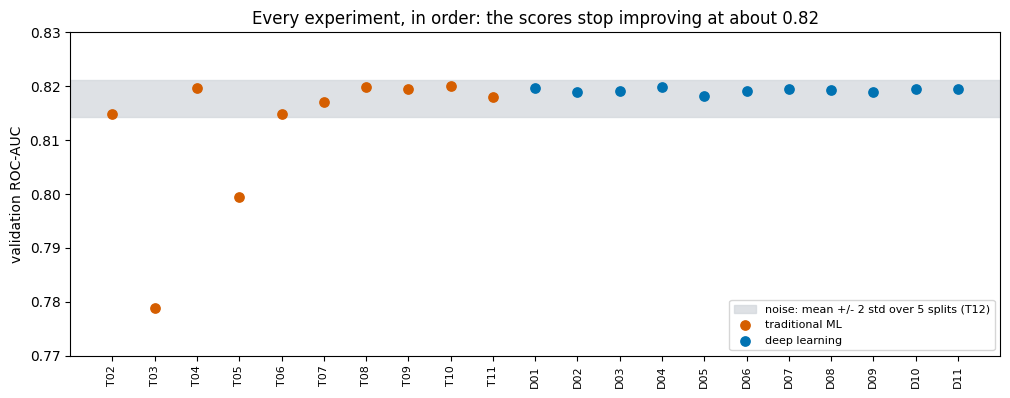

Best ROC-AUC: 0.8200 | models within 0.002 of the best: 16 of 21
Noise (2 std) over 5 splits: 0.0034 | over 5 random starts of the network: 0.0012


In [69]:
trained = table[table["exp_id"] != "T01"].copy()               # the dummy model is not shown (AUC 0.5)
trained = trained[~trained["exp_id"].isin(["T12", "D12"])]      # the repeat experiments are shown as the band instead
trained = trained.sort_values(["step", "exp_id"]).reset_index(drop=True)   # the order the experiments were run: T01-T11, then D01-D11
trained["family"] = np.where(trained["exp_id"].str.startswith("T"), "traditional ML", "deep learning")

fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(trained))
ax.axhspan(gb_mean["roc_auc"] - 2 * gb_std["roc_auc"], gb_mean["roc_auc"] + 2 * gb_std["roc_auc"], color="#d1d5db", alpha=0.7,
           label="noise: mean +/- 2 std over 5 splits (T12)")
for family, color in [("traditional ML", ORANGE), ("deep learning", BLUE)]:
    part = trained[trained["family"] == family]
    ax.scatter(x[part.index], part["roc_auc"], color=color, s=45, label=family, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(trained["exp_id"], rotation=90, fontsize=8)
ax.set_ylabel("validation ROC-AUC"); ax.set_ylim(0.77, 0.83)
ax.set_title("Every experiment, in order: the scores stop improving at about 0.82")
ax.legend(loc="lower right", fontsize=8)
save_and_show("cmp01_progression")

best_auc = trained["roc_auc"].max()
print(f"Best ROC-AUC: {best_auc:.4f} | models within 0.002 of the best: {(trained['roc_auc'] >= best_auc - 0.002).sum()} of {len(trained)}")
print(f"Noise (2 std) over 5 splits: {2 * gb_std['roc_auc']:.4f} | over 5 random starts of the network: {2 * nn_std['roc_auc']:.4f}")

### 48.2 Precision against recall: what the imbalance handling changes
Each point is one experiment, evaluated at the 0.5 cut-off. Models trained with class weights or SMOTE sit in a different place from models trained without help, even though their ROC-AUC is the same.

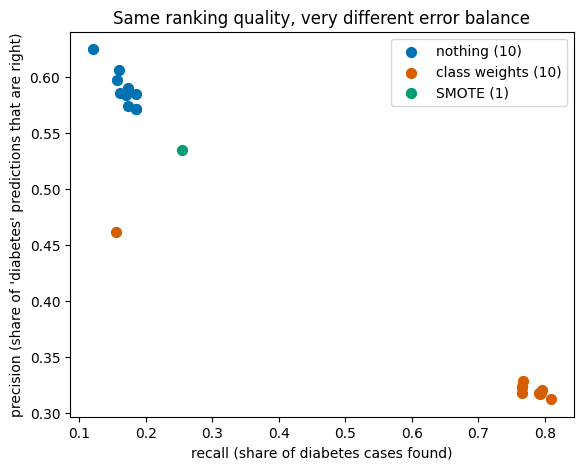

               roc_auc  recall  precision  accuracy
imbalance                                          
SMOTE            0.818   0.255      0.535     0.852
class weights    0.812   0.721      0.334     0.725
nothing          0.819   0.167      0.589     0.855


In [70]:
def imbalance_method(row):
    # How was the class imbalance handled in this experiment?
    if "SMOTE" in row["features"]:
        return "SMOTE"
    if "balanced" in row["hyperparameters"] or "'class_weights': True" in row["hyperparameters"]:
        return "class weights"
    return "nothing"

trained["imbalance"] = trained.apply(imbalance_method, axis=1)
colors = {"nothing": BLUE, "class weights": ORANGE, "SMOTE": "#009E73"}

fig, ax = plt.subplots(figsize=(6.5, 5))
for method, color in colors.items():
    part = trained[trained["imbalance"] == method]
    ax.scatter(part["recall"], part["precision"], color=color, s=50, label=f"{method} ({len(part)})", zorder=3)
ax.set_xlabel("recall (share of diabetes cases found)"); ax.set_ylabel("precision (share of 'diabetes' predictions that are right)")
ax.set_title("Same ranking quality, very different error balance"); ax.legend()
save_and_show("cmp02_precision_recall_tradeoff")
print(trained.groupby("imbalance")[["roc_auc", "recall", "precision", "accuracy"]].mean().round(3))

### 48.3 Cost against quality
Training time on a log scale against ROC-AUC. The model that is cheapest to train for a given quality is the one to prefer when the scores are tied.

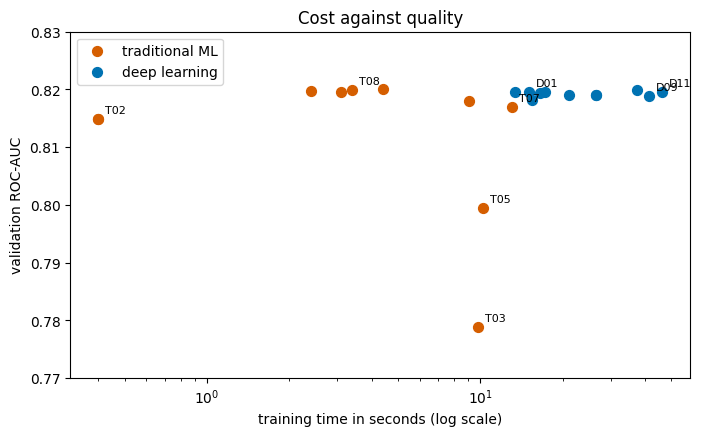

,exp_id,model,roc_auc,train_seconds
0,T02,Logistic regression,0.8149,0.4
4,T06,Logistic regression (tuned),0.8149,0.4
2,T04,Gradient boosting,0.8197,2.4
7,T09,"Gradient boosting (tuned), no engineered features",0.8195,3.1
6,T08,Gradient boosting (tuned),0.8199,3.4


In [71]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for family, color in [("traditional ML", ORANGE), ("deep learning", BLUE)]:
    part = trained[trained["family"] == family]
    ax.scatter(part["train_seconds"].clip(lower=0.1), part["roc_auc"], color=color, s=50, label=family, zorder=3)
for _, r in trained[trained["exp_id"].isin(["T02", "T03", "T05", "T07", "T08", "D01", "D09", "D11"])].iterrows():
    ax.annotate(r["exp_id"], (max(r["train_seconds"], 0.1), r["roc_auc"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("training time in seconds (log scale)"); ax.set_ylabel("validation ROC-AUC")
ax.set_ylim(0.77, 0.83); ax.set_title("Cost against quality"); ax.legend()
save_and_show("cmp03_cost_vs_quality")
trained[["exp_id", "model", "roc_auc", "train_seconds"]].sort_values("train_seconds").head(5)

## 49. Observations for the repeat experiments

In [72]:
repeat_observations = {
    "T12": f"Same model on 5 random splits: ROC-AUC {gb_mean['roc_auc']:.4f} +/- {gb_std['roc_auc']:.4f} (std), range {gb_repeats['roc_auc'].min():.4f} to {gb_repeats['roc_auc'].max():.4f}. Differences below about {2 * gb_std['roc_auc']:.4f} between experiments are within the split noise.",
    "D12": f"Same network with 5 random starts: ROC-AUC {nn_mean['roc_auc']:.4f} +/- {nn_std['roc_auc']:.4f} (std), range {nn_repeats['roc_auc'].min():.4f} to {nn_repeats['roc_auc'].max():.4f}. Noise from the starting weights alone is about {2 * nn_std['roc_auc']:.4f} (2 std).",
}
tracker.set_observations(repeat_observations)

# The saved tables are written again so that they include these last two observations
table = tracker.read()
table["builds_on"] = table["exp_id"].map(lambda i: lineage[i][0])
table["single_change"] = table["exp_id"].map(lambda i: lineage[i][1])
full_table = table[full_columns]
full_table.to_csv(REPORTS / "experiment_table.csv", index=False)
write_markdown_table(full_table, REPORTS / "experiment_table.md")
full_table[full_table["exp_id"].isin(["T12", "D12"])][["exp_id", "model", "roc_auc", "observations"]]

,exp_id,model,roc_auc,observations
11,D12,"Neural net 64-32, mean of 5 random starts",0.8192,Same network with 5 random starts: ROC-AUC 0.8...
23,T12,"Gradient boosting (tuned), mean of 5 splits",0.8178,Same model on 5 random splits: ROC-AUC 0.8178 ...


## 50. Files of this step
- `reports/experiment_table.csv` and `reports/experiment_table.md`: the complete experiment table (24 rows, with settings, split, metrics, time, lineage and observations).
- `reports/experiment_log.csv`: the raw log written by the tracker during the runs.
- `logs/tensorboard/`: one run per experiment (view with `.venv/bin/tensorboard --logdir logs/tensorboard`).
- `logs/*.log` and `logs/training_csv/`: text logs and epoch-by-epoch logs.
- `images/cmp01..cmp03`: the comparison figures.

In [73]:
print("Rows in experiment_table.csv:", len(pd.read_csv(REPORTS / "experiment_table.csv")))
print("TensorBoard runs:", len(list((LOGS / "tensorboard").iterdir())))

Rows in experiment_table.csv: 24
TensorBoard runs: 28


## 51. Step 6 summary

**Facts from the output above:**
- The complete experiment table has **24 experiments**: 11 traditional (T01 to T11), 11 deep learning (D01 to D11) and 2 repeat experiments (T12, D12). It is saved in `reports/experiment_table.csv` and `reports/experiment_table.md`, with the settings, split, metrics, training time, the experiment each one builds on, the single change, and a note.
- **Audit passed:** all 24 values match their TensorBoard run, and the epoch counts of all 11 networks match their CSV logs.
- **Noise:** the tuned gradient boosting model scores ROC-AUC 0.8178 +/- 0.0017 over 5 random splits (range 0.8158 to 0.8199). The baseline network scores 0.8192 +/- 0.0006 over 5 random starts (range 0.8186 to 0.8202). Two standard deviations are 0.0034 and 0.0012.
- **Plateau:** 16 of the 21 trained models are within 0.002 of the best ROC-AUC (0.8200).
- **Differences larger than the noise:** the untuned random forest (0.7788), the SVM on a sample (0.7995) and logistic regression (0.8149, about 0.005 below the best).
- **Differences inside the noise:** tuned boosting against tuned random forest (0.0029), the engineered features (0.0004), dropout (0.0003) and the choice of optimizer. Batch normalization (-0.0015 against D01) is only slightly outside the start-to-start noise, so it may be a small real effect.
- **Class imbalance:** models trained with class weights find on average 72% of diabetes cases with a precision of 0.33; models without any help find 17% with a precision of 0.59; the single SMOTE run finds 26% with a precision of 0.54. The ranking quality (ROC-AUC) is about the same.
- **Cost:** logistic regression trains in 0.4 s (AUC 0.8149), the tuned boosting model in about 4 s (0.8199), a network in 12 to 48 s (about 0.819).
- **Caution:** the noise was measured only for two models, and by changing the split. Comparisons made on one fixed split are paired, so the true noise for them may be smaller. The test set has **not** been used yet.

**To write in my own words before the report:**
1. Using the noise measured here, which differences between my experiments are real and which are not? Give two examples of each.
2. Why do class weights change precision and recall but not the ROC-AUC?
3. Looking at the cost against quality plot, which model would I choose to use, and why?

---
# Step 7: Error analysis on the test set

**The rule for the test set.** I chose the two models using the **validation** set only: the tuned gradient boosting model (T08) and the neural network D04, as decided by the fixed rule in Steps 4 and 5. Now I use the **test set for the first time**, and only for these two models, so the test result is an honest estimate of how they behave on new people. Anything I tune here (decision thresholds) is tuned on the validation set and then applied to the test set.

| Question | Section |
|---|---|
| How good are the two models on new data, and is the score stable? | 53, 54 |
| What kinds of mistakes do they make? (confusion matrices) | 55 |
| What is the trade-off between finding cases and false alarms? (ROC, precision-recall, thresholds) | 56, 57 |
| Can the predicted probabilities be trusted as risks? (calibration) | 58 |
| Is the limit caused by bias or by variance? (train against validation) | 59 |
| Who does the model get wrong? (subgroups and the profile of the mistakes) | 60, 61 |
| What would I try next? | 62 |

## 52. Load the two saved models and score the test set

In [74]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, average_precision_score, f1_score, precision_score, recall_score

tracker = ExperimentTracker(REPORTS / "experiment_log.csv", LOGS / "tensorboard", LOGS / "step7_error_analysis.log")

# Load the models from the saved files (this also proves that the saved files work)
trad_pipeline = joblib.load(MODELS / "best_traditional_model.joblib")           # takes the raw answer columns
dl_model = keras.models.load_model(MODELS / "best_deep_learning_model.keras")   # takes the scaled features

name_trad = f"{results[best_id]['name']} ({best_id})"
name_dl = f"{best_dl['name']} ({best_dl_id})"
print("Traditional model:", name_trad)
print("Deep learning model:", name_dl)

test_ds = make_dataset(test_scaled, y_test, shuffle=False)
val_scores = {name_trad: trad_pipeline.predict_proba(X_val)[:, 1], name_dl: dl_model.predict(val_ds, verbose=0).ravel()}
test_scores = {name_trad: trad_pipeline.predict_proba(X_test)[:, 1], name_dl: dl_model.predict(test_ds, verbose=0).ravel()}

# The reloaded models must give the same validation scores as in the earlier steps
print("Largest difference to the earlier validation scores:",
      float(np.abs(val_scores[name_trad] - results[best_id]["score"]).max()), "/",
      float(np.abs(val_scores[name_dl] - best_dl["score"]).max()))
y_test_values = y_test.values
print("Test set:", len(y_test_values), "people, diabetes share", round(y_test_values.mean(), 4))

Traditional model: Gradient boosting (tuned) (T08)
Deep learning model: Neural net 64-32 + dropout 0.3 (D04)


Largest difference to the earlier validation scores: 0.0 / 0.0
Test set: 34422 people, diabetes share 0.153


## 53. Test results at the usual cut-off of 0.5
The dummy model is the baseline. The validation columns come from earlier steps; the gap between validation and test shows whether the models generalise. The noise measured in Step 6 (two standard deviations about 0.003 for boosting) tells me how large a gap would be surprising.

In [75]:
dummy = results["T01"]["model"]
dummy_val, dummy_test = dummy.predict_proba(val_scaled)[:, 1], dummy.predict_proba(test_scaled)[:, 1]

rows = []
for name, v_scores, t_scores in [("Dummy baseline (T01)", dummy_val, dummy_test),
                                 (name_trad, val_scores[name_trad], test_scores[name_trad]),
                                 (name_dl, val_scores[name_dl], test_scores[name_dl])]:
    m_val, m_test = evaluate_binary(y_val.values, v_scores), evaluate_binary(y_test_values, t_scores)
    rows.append({"model": name, **{f"test {k}": round(v, 4) for k, v in m_test.items()},
                 "val ROC-AUC": round(m_val["roc_auc"], 4), "test minus val ROC-AUC": round(m_test["roc_auc"] - m_val["roc_auc"], 4)})
test_results = pd.DataFrame(rows).set_index("model")
test_results.to_csv(REPORTS / "test_results.csv")
for name in test_results.index:
    tracker.logger.info("TEST | %s | %s", name, test_results.loc[name].to_dict())
test_results

18:20:26 | TEST | Dummy baseline (T01) | {'test accuracy': 0.847, 'test precision': 0.0, 'test recall': 0.0, 'test f1': 0.0, 'test roc_auc': 0.5, 'test pr_auc': 0.153, 'val ROC-AUC': 0.5, 'test minus val ROC-AUC': 0.0}


18:20:26 | TEST | Gradient boosting (tuned) (T08) | {'test accuracy': 0.7055, 'test precision': 0.3157, 'test recall': 0.7926, 'test f1': 0.4516, 'test roc_auc': 0.8159, 'test pr_auc': 0.437, 'val ROC-AUC': 0.8199, 'test minus val ROC-AUC': -0.004}


18:20:26 | TEST | Neural net 64-32 + dropout 0.3 (D04) | {'test accuracy': 0.8535, 'test precision': 0.615, 'test recall': 0.1123, 'test f1': 0.1898, 'test roc_auc': 0.8172, 'test pr_auc': 0.4403, 'val ROC-AUC': 0.8199, 'test minus val ROC-AUC': -0.0027}


,test accuracy,test precision,test recall,test f1,test roc_auc,test pr_auc,val ROC-AUC,test minus val ROC-AUC
model,,,,,,,,
Dummy baseline (T01),0.8470,0.0000,0.0000,0.0000,0.5000,0.1530,0.5000,0.0000
Gradient boosting (tuned) (T08),0.7055,0.3157,0.7926,0.4516,0.8159,0.4370,0.8199,-0.0040
Neural net 64-32 + dropout 0.3 (D04),0.8535,0.6150,0.1123,0.1898,0.8172,0.4403,0.8199,-0.0027


**How to read it.** If the test ROC-AUC is close to the validation ROC-AUC (within the noise), the models generalise and the validation set did not mislead me. The precision and recall of the two models are very different at the 0.5 cut-off because D04 was trained without class weights and T08 with them. That is a difference in the *cut-off behaviour*, not in how well the models rank people, which is why I also compare them at matched operating points in section 57.

## 54. How certain are these test numbers? Bootstrap confidence intervals
The test set is a sample of people. To see how much the scores could change with a different sample, I resample the test set with replacement 500 times and recompute the scores each time. The 95% interval is the range that contains the middle 95% of the results. I also resample the **difference** in ROC-AUC between the two models, using the same resampled people for both.

In [76]:
rng = np.random.default_rng(SEED)
n_test = len(y_test_values)
boot = {name_trad: {"roc_auc": [], "pr_auc": [], "f1": []}, name_dl: {"roc_auc": [], "pr_auc": [], "f1": []}}
auc_difference = []

for _ in range(500):
    pick = rng.integers(0, n_test, n_test)                    # n_test people drawn with replacement
    y_b = y_test_values[pick]
    for name in (name_trad, name_dl):
        s_b = test_scores[name][pick]
        boot[name]["roc_auc"].append(roc_auc_score(y_b, s_b))
        boot[name]["pr_auc"].append(average_precision_score(y_b, s_b))
        boot[name]["f1"].append(f1_score(y_b, (s_b >= 0.5).astype(int)))
    auc_difference.append(boot[name_trad]["roc_auc"][-1] - boot[name_dl]["roc_auc"][-1])

rows = []
for name in (name_trad, name_dl):
    row = {"model": name}
    for metric in ("roc_auc", "pr_auc", "f1"):
        low, high = np.percentile(boot[name][metric], [2.5, 97.5])
        row[metric] = f"{np.mean(boot[name][metric]):.4f}  [{low:.4f}, {high:.4f}]"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))

low, high = np.percentile(auc_difference, [2.5, 97.5])
print(f"ROC-AUC difference (traditional minus neural network): mean {np.mean(auc_difference):+.4f}, 95% interval [{low:+.4f}, {high:+.4f}]")
print("The interval contains 0, so the two models cannot be told apart." if low <= 0 <= high else "The interval does not contain 0, so one model is better.")

,roc_auc,pr_auc,f1
model,,,
Gradient boosting (tuned) (T08),"0.8160 [0.8102, 0.8215]","0.4375 [0.4235, 0.4505]","0.4519 [0.4432, 0.4616]"
Neural net 64-32 + dropout 0.3 (D04),"0.8174 [0.8114, 0.8226]","0.4409 [0.4269, 0.4535]","0.1897 [0.1777, 0.2028]"


ROC-AUC difference (traditional minus neural network): mean -0.0014, 95% interval [-0.0027, -0.0002]
The interval does not contain 0, so one model is better.


**Caution.** The bootstrap only measures the effect of *which people* are in the test set. It does not measure the effect of the random split or of the random start of a network (that was Step 6), and it assumes that the people are independent of each other.

## 55. Confusion matrices: what kinds of mistakes?
Each row is the true situation and each column the prediction. The **false negatives** (diabetes missed) and the **false positives** (false alarms) have different consequences in a screening setting: a missed case may go untreated, while a false alarm means an unnecessary follow-up test.

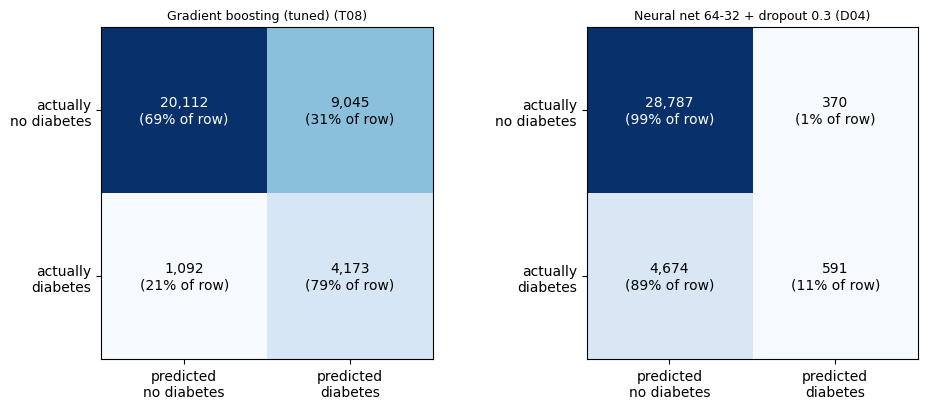

Gradient boosting (tuned) (T08): per 1,000 people -> 153 have diabetes; the model finds 121, misses 32, and raises 263 false alarms (68% of everyone it flags is a false alarm).
Neural net 64-32 + dropout 0.3 (D04): per 1,000 people -> 153 have diabetes; the model finds 17, misses 136, and raises 11 false alarms (39% of everyone it flags is a false alarm).


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, (name_trad, name_dl)):
    predicted = (test_scores[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test_values, predicted)
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["predicted\nno diabetes", "predicted\ndiabetes"]); ax.set_yticklabels(["actually\nno diabetes", "actually\ndiabetes"])
    ax.set_title(name, fontsize=9)
plt.tight_layout()
save_and_show("err01_confusion_matrices_test")

# The same numbers per 1,000 people screened, in words
for name in (name_trad, name_dl):
    predicted = (test_scores[name] >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_values, predicted).ravel()
    scale = 1000 / len(y_test_values)
    print(f"{name}: per 1,000 people -> {y_test_values.mean() * 1000:.0f} have diabetes; the model finds {tp * scale:.0f}, misses {fn * scale:.0f}, "
          f"and raises {fp * scale:.0f} false alarms ({fp / (fp + tp):.0%} of everyone it flags is a false alarm).")

## 56. ROC and precision-recall curves on the test set
- The **ROC curve** shows the true positive rate (recall) against the false positive rate for every possible cut-off. The area under it (ROC-AUC) is the chance that a randomly chosen person with diabetes gets a higher score than a randomly chosen person without it.
- The **precision-recall curve** shows precision against recall. When the positive class is rare (here 15%), it is more informative than the ROC curve, because the number of true negatives is huge and makes the ROC curve look good. The dotted line is the precision of a model with no skill (the share of diabetes).
- The markers show the 0.5 cut-off.

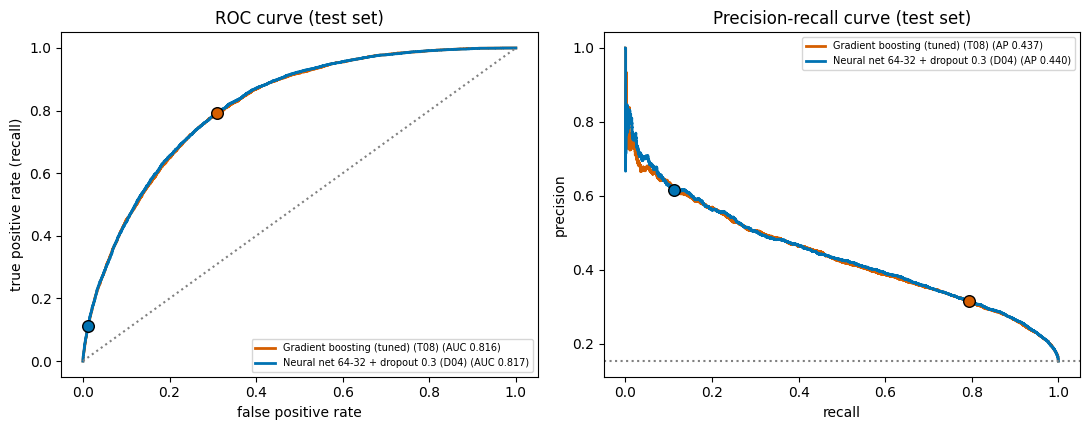

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name, color in [(name_trad, ORANGE), (name_dl, BLUE)]:
    scores = test_scores[name]
    fpr, tpr, _ = roc_curve(y_test_values, scores)
    prec, rec, _ = precision_recall_curve(y_test_values, scores)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(y_test_values, scores):.3f})")
    axes[1].plot(rec, prec, color=color, lw=2, label=f"{name} (AP {average_precision_score(y_test_values, scores):.3f})")
    pred = scores >= 0.5                                  # the 0.5 cut-off as a marker on both curves
    axes[0].scatter(pred[y_test_values == 0].mean(), pred[y_test_values == 1].mean(), color=color, s=70, edgecolor="black", zorder=3)
    axes[1].scatter(pred[y_test_values == 1].mean(), y_test_values[pred].mean(), color=color, s=70, edgecolor="black", zorder=3)
axes[0].plot([0, 1], [0, 1], ":", color="grey"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].axhline(y_test_values.mean(), color="grey", ls=":"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve (test set)"); axes[1].legend(fontsize=7)
plt.tight_layout()
save_and_show("err02_roc_pr_test")

## 57. Choosing a cut-off: the trade-off between finding cases and false alarms
The 0.5 cut-off is just a convention. A different cut-off moves a model along its precision-recall curve. I choose three cut-offs **on the validation set only**, and then apply them to the test set:

1. **0.5**, the convention.
2. **Best F1:** the cut-off with the highest F1 on the validation set (a balance of precision and recall).
3. **Screening:** the highest cut-off that still finds at least **80% of the diabetes cases** on the validation set.

This puts the two models at comparable operating points.

In [79]:
def threshold_best_f1(y_true, scores):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f1)])

def threshold_for_recall(y_true, scores, target=0.80):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    ok = np.where(rec[:-1] >= target)[0]                  # all cut-offs that still find enough cases
    return float(thr[ok.max()])                           # the highest of them (fewest false alarms)

rows = []
for name in (name_trad, name_dl):
    cutoffs = {"cut-off 0.5": 0.5,
               "best F1 on validation": threshold_best_f1(y_val.values, val_scores[name]),
               "recall >= 0.80 on validation": threshold_for_recall(y_val.values, val_scores[name])}
    for rule, cutoff in cutoffs.items():
        pred = (test_scores[name] >= cutoff).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test_values, pred).ravel()
        rows.append({"model": name, "cut-off rule": rule, "cut-off": round(cutoff, 3), "people flagged": f"{pred.mean():.1%}",
                     "recall": round(tp / (tp + fn), 3), "precision": round(tp / (tp + fp), 3), "F1": round(f1_score(y_test_values, pred), 3),
                     "accuracy": round((tp + tn) / len(pred), 3), "false alarms per 1000": round(fp * 1000 / len(pred)),
                     "missed cases per 1000": round(fn * 1000 / len(pred))})
operating_points = pd.DataFrame(rows)
operating_points.to_csv(REPORTS / "operating_points_test.csv", index=False)
operating_points

,model,cut-off rule,cut-off,people flagged,recall,precision,F1,accuracy,false alarms per 1000,missed cases per 1000
0,Gradient boosting (tuned) (T08),cut-off 0.5,0.500,38.4%,0.793,0.316,0.452,0.706,263,32
1,Gradient boosting (tuned) (T08),best F1 on validation,0.642,24.3%,0.609,0.384,0.471,0.791,149,60
2,Gradient boosting (tuned) (T08),recall >= 0.80 on validation,0.492,39.2%,0.798,0.312,0.448,0.699,270,31
3,Neural net 64-32 + dropout 0.3 (D04),cut-off 0.5,0.500,2.8%,0.112,0.615,0.190,0.853,11,136
4,Neural net 64-32 + dropout 0.3 (D04),best F1 on validation,0.236,25.3%,0.631,0.382,0.476,0.787,156,56
5,Neural net 64-32 + dropout 0.3 (D04),recall >= 0.80 on validation,0.155,38.8%,0.796,0.314,0.451,0.703,266,31


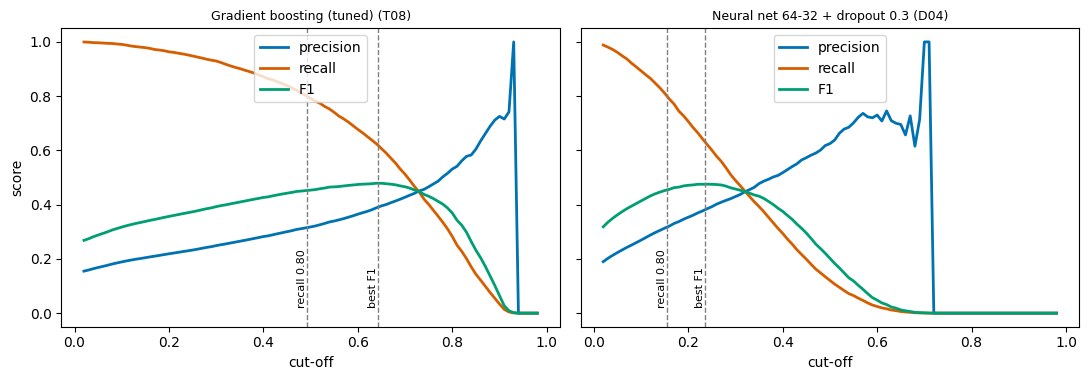

In [80]:
# Precision, recall and F1 against the cut-off (validation set), with the three chosen cut-offs
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, name in zip(axes, (name_trad, name_dl)):
    cut = np.linspace(0.02, 0.98, 97)
    scores = val_scores[name]
    p = [precision_score(y_val.values, scores >= c, zero_division=0) for c in cut]
    r = [recall_score(y_val.values, scores >= c) for c in cut]
    f = [f1_score(y_val.values, scores >= c) for c in cut]
    ax.plot(cut, p, color=BLUE, lw=2, label="precision"); ax.plot(cut, r, color=ORANGE, lw=2, label="recall"); ax.plot(cut, f, color="#009E73", lw=2, label="F1")
    for rule, c in [("best F1", threshold_best_f1(y_val.values, scores)), ("recall 0.80", threshold_for_recall(y_val.values, scores))]:
        ax.axvline(c, color="grey", ls="--", lw=1); ax.text(c, 0.02, rule, rotation=90, va="bottom", ha="right", fontsize=8)
    ax.set_xlabel("cut-off"); ax.set_title(name, fontsize=9); ax.legend(loc="upper center")
axes[0].set_ylabel("score")
plt.tight_layout()
save_and_show("err03_threshold_curves")

## 58. Can the scores be read as probabilities? Calibration
A model is **calibrated** if, among the people it gives a score of about 0.3, about 30% really have diabetes. This matters if the score is shown to a person as a "risk". The plot compares the average score with the real share of diabetes in 10 groups of people (sorted by score). A model on the diagonal is calibrated. The Brier score is the average squared error of the probabilities (lower is better).

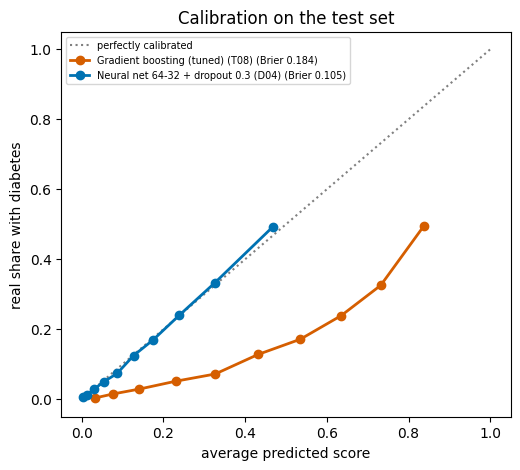

Gradient boosting (tuned) (T08): average score 0.398 against real diabetes share 0.153
Neural net 64-32 + dropout 0.3 (D04): average score 0.152 against real diabetes share 0.153


In [81]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], ":", color="grey", label="perfectly calibrated")
for name, color in [(name_trad, ORANGE), (name_dl, BLUE)]:
    share_diabetes, mean_score = calibration_curve(y_test_values, test_scores[name], n_bins=10, strategy="quantile")
    ax.plot(mean_score, share_diabetes, marker="o", color=color, lw=2, label=f"{name} (Brier {brier_score_loss(y_test_values, test_scores[name]):.3f})")
ax.set_xlabel("average predicted score"); ax.set_ylabel("real share with diabetes"); ax.set_title("Calibration on the test set"); ax.legend(fontsize=7)
save_and_show("err04_calibration")
for name in (name_trad, name_dl):
    print(f"{name}: average score {test_scores[name].mean():.3f} against real diabetes share {y_test_values.mean():.3f}")

The model trained with class weights (T08) gives scores that are too high on average: the weights make the diabetes class count about 5 times more, so its scores are *not* probabilities. The network trained without weights (D04) is close to the diagonal. If risk scores were shown to people, the weighted model would need to be recalibrated first (for example on the validation set).

## 59. Bias and variance: is the model too simple or too flexible?
- **High bias (underfitting):** the model is too simple, so it scores poorly on the training data *and* on new data.
- **High variance (overfitting):** the model is too flexible, so it scores very well on the training data but clearly worse on new data.

I compare the ROC-AUC on a 30,000-row sample of the training set with the ROC-AUC on the validation set. The **test set is not used here**, so that it stays a clean estimate for the two chosen models.

In [82]:
sample = np.random.RandomState(SEED).choice(len(train_scaled), 30000, replace=False)
train_part, y_train_part = train_scaled.iloc[sample], y_train.iloc[sample].values

def score_with(model, frame):
    # Scores for a scikit-learn model or a Keras network.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(frame)[:, 1]
    return model.predict(frame.values.astype("float32"), batch_size=1024, verbose=0).ravel()

models_to_check = [("Logistic regression (T06)", results["T06"]["model"]),
                   ("Random forest, unlimited depth (T03)", results["T03"]["model"]),
                   ("Random forest, tuned (T07)", results["T07"]["model"]),
                   ("Gradient boosting, tuned (T08)", results["T08"]["model"]),
                   ("Neural network 128-64-32 (D02)", dl_results["D02"]["model"]),
                   ("Neural network + dropout (D04)", dl_results["D04"]["model"])]
rows = []
for name, model in models_to_check:
    train_auc = roc_auc_score(y_train_part, score_with(model, train_part))
    val_auc = roc_auc_score(y_val.values, score_with(model, val_scaled))
    rows.append({"model": name, "train ROC-AUC": round(train_auc, 4), "validation ROC-AUC": round(val_auc, 4), "gap (train - validation)": round(train_auc - val_auc, 4)})
bias_variance = pd.DataFrame(rows).set_index("model")
bias_variance

,train ROC-AUC,validation ROC-AUC,gap (train - validation)
model,,,
Logistic regression (T06),0.8047,0.8149,-0.0103
"Random forest, unlimited depth (T03)",0.9998,0.7788,0.2211
"Random forest, tuned (T07)",0.8329,0.8170,0.0159
"Gradient boosting, tuned (T08)",0.8158,0.8199,-0.0042
Neural network 128-64-32 (D02),0.8188,0.8190,-0.0002
Neural network + dropout (D04),0.8142,0.8199,-0.0058


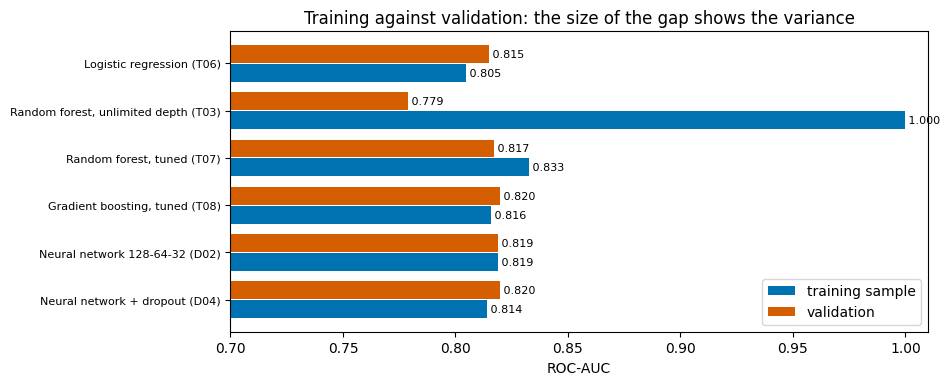

In [83]:
fig, ax = plt.subplots(figsize=(9, 3.9))
positions = np.arange(len(bias_variance))
ax.barh(positions + 0.2, bias_variance["train ROC-AUC"], height=0.38, color=BLUE, label="training sample")
ax.barh(positions - 0.2, bias_variance["validation ROC-AUC"], height=0.38, color=ORANGE, label="validation")
ax.set_yticks(positions); ax.set_yticklabels(bias_variance.index, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0.7, 1.01); ax.set_xlabel("ROC-AUC"); ax.set_title("Training against validation: the size of the gap shows the variance"); ax.legend(loc="lower right")
for i, (t, v) in enumerate(zip(bias_variance["train ROC-AUC"], bias_variance["validation ROC-AUC"])):
    ax.text(t, i + 0.2, f" {t:.3f}", va="center", fontsize=8); ax.text(v, i - 0.2, f" {v:.3f}", va="center", fontsize=8)
save_and_show("err05_bias_variance")

The learning curves from the earlier steps are the other half of the evidence: the boosting loss curve (`ml01_boosting_curve.png`), the training-size curve (`ml05_learning_curve_size.png`) and the network curves (`dl_learning_curves_*.png`). Together with the table above they let me say whether the plateau at ROC-AUC 0.82 comes from a model that is too simple, a model that is too flexible, or from a limit in the data.

## 60. Who does the model get wrong? Errors by subgroup
For the selected traditional model at the 0.5 cut-off, I compute the recall (share of diabetes cases found) and the false positive rate (share of healthy people wrongly flagged) within groups of people. Large differences between groups mean the model does not work equally well for everyone. These are *descriptions of the model's errors*, not explanations of why they happen, and some groups are small.

In [84]:
features_test = X_test.reset_index(drop=True)
scores_trad = test_scores[name_trad]

groups = {
    "Age group": pd.cut(features_test["Age"], [0, 4, 8, 11, 13], labels=["18-39", "40-59", "60-74", "75+"]),
    "BMI category": features_test["bmi_category"].map({0: "underweight", 1: "normal", 2: "overweight", 3: "obese"}),
    "Sex": features_test["Sex"].map({0.0: "female", 1.0: "male"}),
    "Income": pd.cut(features_test["Income"], [0, 3, 6, 8], labels=["low (1-3)", "middle (4-6)", "high (7-8)"]),
    "Education": pd.cut(features_test["Education"], [0, 4, 6], labels=["no college degree", "college graduate"]),
}

def subgroup_table(labels, scores, cutoff=0.5):
    rows = []
    for group in pd.Series(labels).dropna().unique():
        mask = (labels == group).values
        y_g, s_g = y_test_values[mask], scores[mask]
        flagged = s_g >= cutoff
        rows.append({"group": group, "people": int(mask.sum()), "diabetes share": round(y_g.mean(), 3), "flagged share": round(flagged.mean(), 3),
                     "recall": round(flagged[y_g == 1].mean(), 3), "false positive rate": round(flagged[y_g == 0].mean(), 3),
                     "precision": round(y_g[flagged].mean(), 3) if flagged.any() else np.nan,
                     "ROC-AUC": round(roc_auc_score(y_g, s_g), 3) if len(set(y_g)) == 2 else np.nan})
    return pd.DataFrame(rows)

all_tables = []
for title, labels in groups.items():
    table_g = subgroup_table(labels, scores_trad)
    table_g.insert(0, "variable", title)
    all_tables.append(table_g)
subgroup_errors = pd.concat(all_tables, ignore_index=True)
subgroup_errors.to_csv(REPORTS / "subgroup_errors_test.csv", index=False)
subgroup_errors

,variable,group,people,diabetes share,flagged share,recall,false positive rate,precision,ROC-AUC
0,Age group,75+,4934,0.200,0.589,0.819,0.531,0.279,0.723
1,Age group,40-59,12197,0.126,0.276,0.708,0.214,0.323,0.828
2,Age group,18-39,5122,0.037,0.050,0.378,0.038,0.275,0.855
3,Age group,60-74,12169,0.210,0.550,0.863,0.467,0.330,0.781
4,BMI category,overweight,12394,0.127,0.349,0.735,0.292,0.269,0.791
5,BMI category,obese,12792,0.244,0.602,0.885,0.511,0.359,0.774
6,BMI category,normal,8773,0.061,0.132,0.451,0.112,0.208,0.810
7,BMI category,underweight,463,0.056,0.069,0.231,0.059,0.188,0.802
8,Sex,male,15187,0.166,0.427,0.809,0.351,0.314,0.803
9,Sex,female,19235,0.143,0.350,0.778,0.279,0.318,0.825


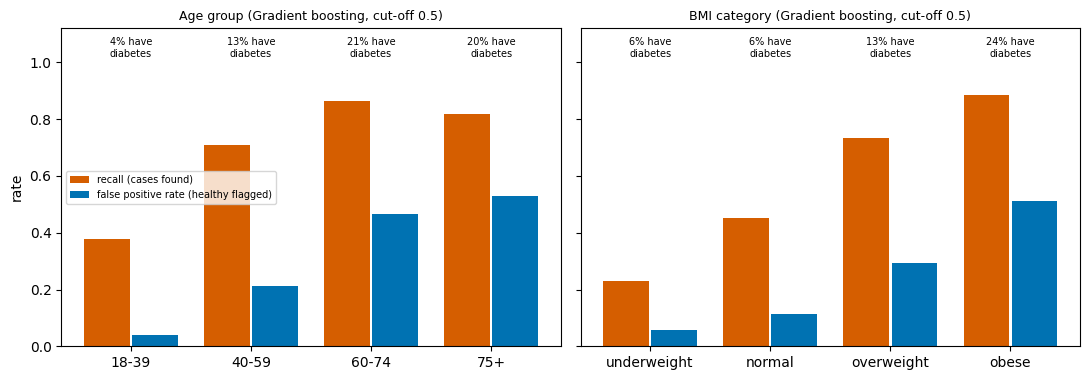

In [85]:
# Recall and false positive rate by age group and by BMI category
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, title, order in [(axes[0], "Age group", ["18-39", "40-59", "60-74", "75+"]), (axes[1], "BMI category", ["underweight", "normal", "overweight", "obese"])]:
    part = subgroup_errors[subgroup_errors["variable"] == title].set_index("group").loc[order]
    x = np.arange(len(order))
    ax.bar(x - 0.2, part["recall"], width=0.38, color=ORANGE, label="recall (cases found)")
    ax.bar(x + 0.2, part["false positive rate"], width=0.38, color=BLUE, label="false positive rate (healthy flagged)")
    ax.set_xticks(x); ax.set_xticklabels(order); ax.set_title(f"{title} ({name_trad.split(' (')[0]}, cut-off 0.5)", fontsize=9)
    for i, share in enumerate(part["diabetes share"]):
        ax.text(i, 1.02, f"{share:.0%} have\ndiabetes", ha="center", fontsize=7)
axes[0].set_ylabel("rate"); axes[0].set_ylim(0, 1.12); axes[0].legend(loc="center left", fontsize=7)
plt.tight_layout()
save_and_show("err06_subgroup_errors")

## 61. What do the mistakes look like?
I compare the average answers of the four groups of the confusion matrix (traditional model, cut-off 0.5): true positives (cases found), false negatives (cases missed), false positives (false alarms) and true negatives. If the missed cases look like the healthy people, the model had no information that could have told them apart.

In [86]:
predicted = (scores_trad >= 0.5).astype(int)
outcome = np.select([(y_test_values == 1) & (predicted == 1), (y_test_values == 1) & (predicted == 0), (y_test_values == 0) & (predicted == 1)],
                    ["found (TP)", "missed (FN)", "false alarm (FP)"], "healthy, not flagged (TN)")
profile_columns = ["Age", "BMI", "GenHlth", "HighBP", "HighChol", "condition_count", "PhysActivity", "DiffWalk", "Income", "poor_health_days"]
profile = features_test[profile_columns].groupby(outcome).mean().T
profile = profile[["found (TP)", "missed (FN)", "false alarm (FP)", "healthy, not flagged (TN)"]].round(2)
print("Number of people in each group:", pd.Series(outcome).value_counts().to_dict())
profile

Number of people in each group: {'healthy, not flagged (TN)': 20112, 'false alarm (FP)': 9045, 'found (TP)': 4173, 'missed (FN)': 1092}


,found (TP),missed (FN),false alarm (FP),"healthy, not flagged (TN)"
Age,9.62,8.35,9.71,7.08
BMI,33.17,27.88,31.32,26.63
GenHlth,3.51,2.48,3.24,2.15
HighBP,0.85,0.39,0.79,0.23
HighChol,0.74,0.41,0.67,0.28
condition_count,2.41,0.96,2.11,0.61
PhysActivity,0.60,0.76,0.64,0.80
DiffWalk,0.45,0.08,0.35,0.06
Income,4.96,5.96,5.26,6.33
poor_health_days,14.04,6.37,11.61,5.61


Read each row across: for example, if the *missed* people have a lower BMI, fewer conditions and better general health than the people the model *found*, they resemble the healthy group on exactly the features the model relies on. This is a description of association in this data, not of causes.

## 62. What I would try next
These are **ideas to test, not results**: none of them has been run. Each is linked to evidence from the sections above.

| Idea | Evidence that motivates it | What I would measure |
|---|---|---|
| Choose the cut-off for the intended use (screening or confirmation) and report the false alarms and misses per 1,000 people | Sections 55 and 57: the same ranking quality gives very different error balances | Precision and recall at the chosen cut-off on new data |
| Recalibrate the class-weighted model before showing a risk number | Section 58: weighted scores are too high | Brier score and the calibration plot after recalibration on validation data |
| Add information the survey does not contain (for example blood glucose or HbA1c, waist size, family history) | The plateau near 0.82 across the 21 trained models (Step 6), and small gaps between training and validation (section 59), suggest that the limit is the information in the 25 features | ROC-AUC with the extra variables |
| Check the performance for each subgroup before any real use, and collect data from the target population | Section 60: the model does not work equally well for every group, and the data are from US adults in 2015 | Subgroup recall and false positive rate on local data |
| Try other model types or more complex networks | Step 6: no model type was clearly better, so I expect small gains at most | Paired comparison on the same splits with repeated runs (as in Step 6) |

## 63. Save the results of this step

In [87]:
print("Saved:", [p.name for p in sorted(REPORTS.glob("*")) if p.name in ("test_results.csv", "operating_points_test.csv", "subgroup_errors_test.csv")])
print("Figures:", sorted(p.name for p in (ROOT / "images").glob("err0*.png")))
tracker.logger.info("step 7 finished: test set used for %s and %s only", name_trad, name_dl)

18:20:46 | step 7 finished: test set used for Gradient boosting (tuned) (T08) and Neural net 64-32 + dropout 0.3 (D04) only


Saved: ['operating_points_test.csv', 'subgroup_errors_test.csv', 'test_results.csv']
Figures: ['err01_confusion_matrices_test.png', 'err02_roc_pr_test.png', 'err03_threshold_curves.png', 'err04_calibration.png', 'err05_bias_variance.png', 'err06_subgroup_errors.png']


## 64. Step 7 summary

**Facts from the output above** (the test set was used only for the two chosen models and the dummy baseline):
- **Test results at the 0.5 cut-off.** Tuned gradient boosting (T08): ROC-AUC 0.8159, PR-AUC 0.437, recall 0.793, precision 0.316, F1 0.452. Neural network D04: ROC-AUC 0.8172, PR-AUC 0.440, recall 0.112, precision 0.615, F1 0.190. The dummy model reaches an accuracy of 0.847 with recall 0.
- **Generalisation.** From validation to test the ROC-AUC fell by 0.0040 (T08) and 0.0027 (D04), small changes of about the size of the noise measured in Step 6. Both models had been selected for having the highest validation score, which tends to make the validation score slightly optimistic.
- **The two models are practically tied.** The paired bootstrap gives a ROC-AUC difference (traditional minus network) of -0.0014 with a 95% interval of [-0.0027, -0.0002]: on these test people the network is slightly better, but the difference is smaller than the split-to-split noise of Step 6 (two standard deviations 0.0034), and the two had the same ROC-AUC on validation (0.8199).
- **Mistakes per 1,000 people** (15% have diabetes, about 153): at the 0.5 cut-off T08 finds 121 cases, misses 32 and raises 263 false alarms (68% of the people it flags are false alarms). D04 finds 17, misses 136 and raises 11 false alarms.
- **At matched cut-offs the two models behave the same.** With the cut-off chosen on the validation set for a recall of at least 0.80, T08 gets recall 0.798 with precision 0.312 and D04 gets recall 0.796 with precision 0.314. With the cut-off for the best F1, the F1 is 0.471 (T08) and 0.476 (D04).
- **Calibration.** The average score of T08 is 0.398 against a real diabetes share of 0.153 (Brier 0.184), so its scores are not probabilities. D04's average score is 0.152 (Brier 0.105) and its curve follows the diagonal.
- **Bias and variance.** The random forest with unlimited depth fits the training sample almost perfectly (ROC-AUC 0.9998) but scores 0.7788 on validation: high variance. The other models have a gap between training and validation between -0.010 and +0.016, and their training ROC-AUC is only 0.80 to 0.83. None of them fits its training data much better than new data, and the more flexible models did not score higher, which is consistent with a limit in the information in the features (a hypothesis, not proof).
- **Subgroups (T08, cut-off 0.5).** Recall is 0.38 for people aged 18-39 but 0.86 for 60-74, and the false positive rate rises from 0.04 to 0.47 and 0.53 for the two oldest groups. Within a group, the ROC-AUC falls from 0.855 (18-39) to 0.723 (75+). By income, the false positive rate is 0.50 for the low group and 0.22 for the high group, while the diabetes share is 24% and 11%.
- **The people who are missed look healthy.** The missed cases have on average 0.96 conditions, a BMI of 27.9 and a general-health score of 2.48, which is closer to the healthy people who were not flagged (0.61, 26.6, 2.15) than to the cases that were found (2.41, 33.2, 3.51). The false alarms resemble the cases that were found.

**To write in my own words before the report:**
1. What does a missed case cost, compared with a false alarm, in a screening setting? Which cut-off would I use and why?
2. Using the bias-variance table and the learning curves, why does the ROC-AUC stop at about 0.82: is the model too simple, too flexible, or is the limit in the data? Which numbers support my answer?
3. What fairness and safety concerns do the subgroup results raise for using this model in practice, and what would I check first?